# Case Study 26 — "Order One Size Up": Size and Fit Prediction from Customer, Product and Review Signals to Cut Fashion Returns

**Priority:** ★★ Good to have · **Reference:** Case Study 26 — *Flipkart: Incorporating customer reviews in size and fit recommendation* (`indian_ecommerce_data_science_case_studies.md`)
**Audience:** Head of Fashion Category, Product (product page), Returns and Reverse Logistics, Finance
**Data:** ⚠️ **SYNTHETIC** (D-26-01). Flipkart's purchase, returns and review data are confidential; this is a simulation calibrated to the class shares the paper documents, with a hidden body-size and garment-fit model.
**Reproducibility:** seed = 42 · `python -m nbconvert --to notebook --execute --inplace cs26_size_fit_returns.ipynb`

## 0. Executive Summary for Business

*(Synthetic orders, returns and reviews with a hidden body-size and garment-fit model, built on the documented design of Flipkart's size and fit recommender: three-class labels from return reason codes, review text as an extra signal, four fashion categories. Flipkart's data, thresholds and business impact are not public, so this is an interview-standard solution on simulated data, not a reproduction of their system. Written after the analysis.)*

- **The question:** which orders should get a "size up / size down" tip, does review text improve the prediction, and how many ₹ crore does the tip save net of tips that backfire?
- **The label is noisy by construction.** Only 50% of truly mismatched orders were returned, so **5.2% of the "fit" class is really mismatched**, and 4.0% of size returns carry the wrong direction. Only 48% of true mismatches carry the right label.
- **History is the strongest signal.** For customers with a usual size, each step above it multiplies the odds of "too large" by **3.9** (95% CI 3.8 to 4.0) and cuts the odds of "too small" to **0.24**. Permuting the history and size-gap features costs 0.111 mAP, brand and fabric 0.088, reviews 0.029.
- **Reviews help, modestly.** Adding review features raises mean average precision (mAP) by **+0.008** for boosting (CI +0.004 to +0.011) and for logistic regression, and macro-F1 by about +0.005 (Holm p = 0.040). Boosting with reviews reaches mAP 0.175 against 0.167 without. The gain is small, as the paper also finds (1% to 4% relative).
- **Macro-F1 is a weak yardstick here.** Always predicting "fit" scores 0.325; logistic regression scores 0.323 and boosting 0.356 (CI 0.352 to 0.359). Ranking quality (mAP, calibration) shows the real signal: the top 1% of scores are right **36%** of the time against a base rate near 3%.
- **Reviews help only if the product has reviews.** The gain for products with 5+ informative reviews is **+0.014** (CI +0.006 to +0.023), with 1 to 4 reviews +0.016, with none **−0.0003** (no gain). For new customers the gain (+0.004, CI −0.001 to +0.009) is not significantly different from returning customers (p = 0.20), so the paper's cold-start motivation is not confirmed on this data.
- **Transfer needs platform data.** A classifier trained only on public English reviews has macro-F1 0.72 on platform fit tags against **0.84** when trained on platform tags (McNemar p < 1e-60); it fails on Hinglish.
- **Money (assumed costs, twin effect):** at the validation-chosen cut-off the tip is shown on **26%** of orders and, if followed, cuts size returns among them from 13.4% to 2.3%. Base case: about **₹3.7 crore a year** net of ₹1.2 crore running cost (2 crore orders, 30% follow, ₹380 per return). **Worst case −₹2.2 crore, best case +₹10.6 crore.** The sign depends on how many customers follow the tip.
- **A/B test:** analysing only flagged orders, a **20% relative drop** in their size-return rate (24% at a top-5% cut-off) needs about **1,100 flagged orders per arm** (23,000 orders, 825 customers); analysing all orders would need 120,000 per arm.
- **I recommend:** pilot the tip in two categories at a cut-off near the top 5% to 10% of orders, measure on triggered orders, and scale only if the A/B shows the follow rate and return drop the base case needs.

## 1. The Problem in Simple English

A large share of online fashion orders come back, and many come back for one reason: **"it didn't fit"**. The customer ordered a Medium, but this brand's Medium runs small, or this customer is between sizes. Each return costs the company **reverse delivery, handling, a markdown on the resold item, and an unhappy customer**. The size labels S, M, L mean different things in different brands, and the brand size charts are slow to use.

The idea: on the product page, show a short tip such as **"Customers say this runs small: consider one size up"**, but only when we are fairly sure. To know when, we predict for each (customer, product, size) order whether it will turn out **too small, a good fit, or too large**. Three kinds of signals help:
- **Customer**: past size returns and the size they usually keep (missing for new customers).
- **Product and size**: brand, fabric, the size being ordered.
- **Reviews**: what other buyers wrote about the fit ("runs small", "size chhota hai"). This is the only signal that works for a **new customer**, and for a **new product** it is missing.

Leaders and interviewers want to know:
1. Do review texts really add predictive power, and for whom (new customers, products with few reviews)?
2. What is the right metric when "small" and "large" are only 2% to 5% of orders each?
3. How noisy is the label "returned with reason *size smaller*", and what does "not returned = fit" hide?
4. How many ₹ crore can a tip save, net of tips that backfire, and how would we prove it in an A/B test?

## 2. Reference from the Case File

### (a) What Flipkart did — *documented*

| Item | Documented fact (from the reference file) |
|---|---|
| Problem | Size-related returns and refunds in e-fashion hurt customers and cost the company; symbolic sizes (S/M/L) vary between and within brands; brand size guides are cumbersome. The paper quotes "up to 40% of online fashion products are returned" from a third-party reference, not Flipkart's own number |
| Question | Given a customer, a product and its reviews, will the product be small, true-to-size or large for this customer, so the platform can show "buy one size larger / smaller" tips? Do review texts help, especially for new customers? |
| Data | Four categories: Women Jacket, Women Kurta and Kurti, Men's Jean, Men's Polo T-shirt. Labels from return reason codes ("Size smaller" / "Size larger"; everything else = fit). Class shares (Table 1): small 4.52% / 3.14% / 2.92% / 2.40% and large 1.68% / 2.76% / 2.35% / 1.30% (jacket / polo / jean / kurta respectively). Customers per category from 1.5 million to 6.2 million |
| Approach | Classification P(fit | customer, product, reviews): three residual-block pathways (product, customer, reviews) with embeddings, then softmax. Each review embedded by a language model (BERT trained on the public ModCloth fit data, BERT fine-tuned on platform fit labels, and a RoBERTa-style model pre-trained on platform text); embeddings averaged per product; a zero vector when there are no reviews. Fit instances were down-weighted by re-sampling. Baseline: a deep model with customer and product features only |
| Metric and result | Macro F1. Baseline macro F1 between 35.6 and 38.3. Best model improves it by 1.37% to 4.31% (relative). Review-only models are worse than the baseline by 8% to 16%. Transfer from ModCloth alone gives 0.43% to 1.94% |
| Evidence limits | 80:10:10 split; **no significance tests, confidence intervals, or seed variance** are reported. **No return-rate, cost or conversion impact** is reported. Launch, thresholds, serving and A/B tests are not disclosed |

**Source:** Chatterjee, Tej and Dasaraju (Flipkart), "Incorporating Customer Reviews in Size and Fit Recommendation systems for Fashion E-Commerce", SIGIR eCom'22, arXiv:2208.06261. The evidence level for the method is strong; for business impact there is none.

### (b) What *we* simulate and add

| Item | Our choice |
|---|---|
| Data | 160,000 customers, 7,000 products in the four documented categories, **≈ 480,000 orders** in a 180-day window, ≈ 47,000 reviews with text (English and Hinglish), a public labelled review set of 6,000 (our stand-in for ModCloth) and a prior-period history for returning customers. Label shares are calibrated to the paper's Table 1. |
| Hidden truth | Each customer has a hidden body size; each product has a hidden "runs small/large" offset; a share of mismatched orders is returned (the rest are silently kept, so they look like "fit"). This lets us measure label noise and run a **digital-twin test of the tip**. |
| Models | Prior (all fit); logistic regression and gradient boosting, each without and with review features; reviews-only; review text classifier trained on public data vs fine-tuned on platform labels |
| Statistics added (the paper has none) | Bootstrap **confidence intervals** for macro-F1 and average precision; **paired** comparisons with Holm correction; results by **cold-start segment** and review volume; logistic odds ratios for the size-gap signal; calibration; **sample size** for the A/B test; twin-based ₹ impact with best/base/worst |

**Honest limits:** the paper gives no code, no thresholds and no impact figure. The feature set, the review model and the business numbers here are our own interview-standard design on simulated data, not a reproduction of Flipkart's system.

### (c) How the industry uses this

"Runs small / true to size" tips and size recommenders are standard on fashion marketplaces (Flipkart, Myntra, Ajio, Amazon Fashion, Zalando, Stitch Fix). Common building blocks are customer size history, brand-level fit statistics from returns, review mining, and body-measurement questionnaires for new customers. In interviews, this case tests label construction from reason codes, imbalanced-class metrics, cold start, and how to size a causal test of a product-page nudge.

## 3. Business Question → Analytical Question → Statistical Hypotheses

| Level | Statement |
|---|---|
| Business | Which orders should get a "size up / size down" tip, and how many ₹ crore does it save in returns after tips that backfire? |
| Analytical | Can we predict the too-small / too-large outcome better than customer and product data alone by adding review text, mainly for cold-start customers and products with few reviews? |

**Hypotheses**
- **H1 (history):** H0: a customer's ordered size relative to their usual size has no effect on the odds of a "too small" or "too large" return (logistic odds ratio = 1).
- **H2 (reviews, overall):** H0: adding review features does not change average precision or macro-F1 (paired bootstrap, Holm across comparisons).
- **H3 (cold start):** H0: the gain from reviews is the same for customers with no history as for customers with history (bootstrap difference in gains), and the same for products with 0, 1 to 4 and 5+ informative reviews.
- **H4 (transfer):** H0: a review classifier trained on public data classifies platform reviews as well as one fine-tuned on platform labels (McNemar).
- **H5 (calibration and tip):** H0: among orders we flag, the rate of the predicted size problem equals the base rate (the flag has no lift).

**Primary metrics:** **macro-F1** (as in the paper, so the result is comparable in kind) and **mean average precision** over the two minority classes (small, large), which does not depend on a cut-off. **Business metric:** size-related returns avoided per 100 tips shown, in the digital twin.

In [1]:
import sys, warnings, importlib, os, time, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, f1_score
from sklearn.utils.class_weight import compute_sample_weight
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportion_confint
import statsmodels.formula.api as smf

SEED = 42
np.random.seed(SEED)
RNG = np.random.default_rng(np.random.SeedSequence(SEED).spawn(1)[0])
warnings.filterwarnings("ignore")
pd.set_option("display.width", 170, "display.max_columns", 30, "display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid"); plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.titleweight": "bold"})
print("ready")

ready


## 4. Data

### 4.1 Sourcing outcome

| Attempt | Result |
|---|---|
| Public Indian fashion purchase and returns data | **None.** Platform returns and reason codes are confidential. |
| Public fit-review data (ModCloth, RentTheRunway) | Exists, but is US data with a different product mix, has no returns, and no known truth. The paper used ModCloth only to train a review classifier; we simulate a public labelled set for the same role. |
| **Decision** | Synthetic orders, returns and reviews with a hidden fit mechanism, calibrated to the documented class shares, so that label noise and the effect of a tip can be measured (D-26-01) |

### 4.2 Generator — clearly marked section

In [2]:
%%writefile data/generate_cs26.py
"""
SYNTHETIC DATA GENERATOR - CASE STUDY 26 (Flipkart-style size and fit prediction with customer reviews)
======================================================================================================
THIS DATA IS SYNTHETIC. Flipkart's purchase, returns and review data are confidential.

Documented context (Chatterjee, Tej, Dasaraju, SIGIR eCom'22, arXiv:2208.06261): four fashion categories, labels
derived from return reason codes ("Size smaller" -> small, "Size larger" -> large, everything else -> fit), heavy class
imbalance (Table 1: Women Jacket 4.52% small / 1.68% large, Women Kurta and Kurti 2.40 / 1.30, Men's Jean 2.92 / 2.35,
Men's Polo T-shirt 3.14 / 2.76), review text as an extra signal, cold-start customers, public ModCloth data used for transfer.

Simulation (mechanism is OURS, not the paper's):
  * Each customer has a hidden body size b (continuous). They order a size s = round(b + noise).
  * Each product has a hidden "runs" offset r (brand component + fabric + product-specific): r > 0 means it runs large.
  * Gap g = s + r - b + eps. g < -t_small: garment too small; g > t_large: garment too large.
    Thresholds are calibrated per category so that (mismatch AND returned) reproduces the Table 1 shares.
  * Only a share RHO of mismatched customers return the item; the rest keep it and are labelled "fit" (label noise).
    4% of size returns carry the wrong direction reason code (agent mistake). 6% of orders return for other reasons.
  * Reviews: reviewers perceive small / fit / large from r plus their own noise; ~70% of text mentions fit (English,
    Hinglish, some generic filler); 8% carry the platform's own fit tag. A separate public labelled set (English only,
    different products) plays the role of ModCloth.
  * Customers have a prior-period history (orders, size returns, usual size = mean size of orders kept) except cold-start ones.
Hidden truth (prefixed _) allows a digital-twin test: what would the return reason have been if the tip had changed the size?

Outputs: data/cs26/{customers,products,purchases,reviews,public_fit_reviews}.csv.gz, true_params.npz
"""
import os
import numpy as np
import pandas as pd

SEED = 42
N_CUST, N_PURCH, DAYS = 160_000, 480_000, 180
RHO = 0.5                       # share of mismatched orders actually returned
CATS = ["Women Jacket", "Women Kurta and Kurti", "Men's Jean", "Men's Polo T-shirt"]
GENDER = {0: "F", 1: "F", 2: "M", 3: "M"}
TARGET = {0: (0.0452, 0.0168), 1: (0.0240, 0.0130), 2: (0.0292, 0.0235), 3: (0.0314, 0.0276)}   # documented Table 1
N_PROD = {0: 1200, 1: 3000, 2: 1500, 3: 1300}
N_BRAND = 15
SIZES = ["S-", "S", "M", "L", "XL", "XXL"]
FABRICS = ["cotton", "polyester blend", "stretch denim", "rigid denim", "knit", "wool blend"]
FAB_EFF = {"cotton": 0.0, "polyester blend": -0.12, "stretch denim": 0.05, "rigid denim": -0.18, "knit": 0.10, "wool blend": -0.08}

SMALL_EN = ["runs small", "too tight", "order one size up", "size is smaller than expected", "very snug", "tight fit, go a size larger"]
LARGE_EN = ["runs large", "too loose", "order one size down", "size is bigger than expected", "very baggy", "loose fit, go a size smaller"]
FIT_EN = ["true to size", "perfect fit", "fits as expected", "size is just right", "fit is perfect"]
SMALL_HI = ["size chhota hai", "bahut tight hai", "ek size bada lena", "fitting chhoti aayi"]
LARGE_HI = ["size bada hai", "bahut dheela hai", "ek size chhota lena", "fitting badi aayi"]
FIT_HI = ["size ekdum sahi hai", "fitting badhiya hai", "size perfect aaya"]
FILLER = ["nice fabric", "good colour", "value for money", "delivery was quick", "stitching is decent", "looks good", "packaging was fine", "not bad for the price", "colour slightly different from picture"]
SPAM = ["Awesome product", "Super", "Nice", "Good", "Highly recommended"]


def _phrase(rng, lab, hindi):
    pools = {0: (SMALL_HI, SMALL_EN), 1: (FIT_HI, FIT_EN), 2: (LARGE_HI, LARGE_EN)}
    hi, en = pools[lab]
    return hi[rng.integers(len(hi))] if hindi else en[rng.integers(len(en))]


def _make_reviews(rng, prod_ids, run_lookup, counts, day_lo, day_hi, hindi_share, tag_share):
    pid = np.repeat(prod_ids, counts); n = len(pid); r = run_lookup[pid]
    percept = r + rng.normal(0, 0.7, n); lab = np.where(percept < -0.6, 0, np.where(percept > 0.6, 2, 1))
    flip = rng.random(n) < 0.08; lab = np.where(flip, rng.integers(0, 3, n), lab)          # sloppy reviewers
    hindi = rng.random(n) < hindi_share; has_fit = rng.random(n) < 0.70; texts = []
    for i in range(n):
        parts = [FILLER[rng.integers(len(FILLER))]]
        if has_fit[i]:
            parts.append(_phrase(rng, lab[i], hindi[i]))
        if rng.random() < 0.4:
            parts.append(FILLER[rng.integers(len(FILLER))])
        rng.shuffle(parts); texts.append(", ".join(parts))
    tag = np.where(rng.random(n) < tag_share, np.array(["small", "ok", "large"])[lab], "")
    return pd.DataFrame({"product_id": pid, "day": rng.integers(day_lo, day_hi, n), "review_text": texts, "fit_tag": tag, "rating": np.clip(np.round(rng.normal(4.0 - 0.5 * (lab != 1), 0.9, n)), 1, 5).astype(int), "_perceived": lab})


def generate(seed=SEED):
    rng = np.random.default_rng(seed)
    # ---- customers
    female = rng.random(N_CUST) < 0.55
    body = np.clip(np.where(female, rng.normal(2.2, 1.0, N_CUST), rng.normal(2.6, 1.0, N_CUST)), -0.4, 5.4)
    activity = rng.pareto(2.2, N_CUST) + 1; activity /= activity.sum()
    # ---- products
    prod = []; run = []; pid0 = 0
    brand_eff = {c: rng.normal(0, 0.35, N_BRAND) for c in range(4)}
    for c in range(4):
        n = N_PROD[c]; br = rng.integers(0, N_BRAND, n); fab = rng.choice(FABRICS if c != 2 else ["stretch denim", "rigid denim", "cotton"], n)
        if c == 2: pass
        r = brand_eff[c][br] + np.array([FAB_EFF[f] for f in fab]) + rng.normal(0, 0.35, n)
        newp = rng.random(n) < 0.20; launch = np.where(newp, rng.integers(10, 150, n), -1)
        price = np.round(np.exp(rng.normal(np.log([1700, 600, 1300, 650][c]), 0.45, n)), 0)
        prod.append(pd.DataFrame({"product_id": np.arange(pid0, pid0 + n), "category": CATS[c], "brand": [f"B{c}{b:02d}" for b in br], "fabric": fab, "price_inr": price,
                                  "launch_day": launch, "avg_rating_snapshot": np.clip(np.round(rng.normal(4.0, 0.35, n), 1), 2.5, 5.0), "_runs": r, "_cat": c}))
        pid0 += n
    products = pd.concat(prod, ignore_index=True); run_all = products._runs.values; cat_of = products._cat.values
    # ---- in-window purchases
    cust = rng.choice(N_CUST, N_PURCH, p=activity); is_f = female[cust]
    cat = np.where(is_f, np.where(rng.random(N_PURCH) < 0.28, 0, 1), np.where(rng.random(N_PURCH) < 0.55, 2, 3))
    day = rng.integers(0, DAYS, N_PURCH); prod_idx = np.zeros(N_PURCH, int)
    for c in range(4):
        m = cat == c; ids = products.index[products._cat == c].values; w = rng.pareto(1.4, len(ids)) + 1; w /= w.sum()
        prod_idx[m] = rng.choice(ids, m.sum(), p=w)
    launch = products.launch_day.values[prod_idx]; day = np.where(launch >= 0, np.minimum(DAYS - 1, np.maximum(day, launch + rng.integers(0, 30, N_PURCH))), day)
    size = np.clip(np.round(body[cust] + rng.normal(0, 0.7, N_PURCH)), 0, 5).astype(int)
    g = size + run_all[prod_idx] - body[cust] + rng.normal(0, 0.35, N_PURCH); ret_u = rng.random(N_PURCH)
    ts = np.zeros(4); tl = np.zeros(4)
    for c in range(4):
        m = cat == c; ts[c] = -np.quantile(g[m], TARGET[c][0] / RHO); tl[c] = np.quantile(g[m], 1 - TARGET[c][1] / RHO)
    def reason(g_, u_, c_, rng_):
        mis_s = g_ < -ts[c_]; mis_l = g_ > tl[c_]; ret = u_ < RHO; out = np.full(len(g_), "none", dtype=object)
        out[mis_s & ret] = "size_smaller"; out[mis_l & ret] = "size_larger"; return out
    true_reason = reason(g, ret_u, cat, rng); other = (true_reason == "none") & (rng.random(N_PURCH) < 0.06); obs = true_reason.copy(); obs[other] = "other"
    swap = np.isin(obs, ["size_smaller", "size_larger"]) & (rng.random(N_PURCH) < 0.04)
    obs[swap] = np.where(obs[swap] == "size_smaller", "size_larger", "size_smaller")
    purchases = pd.DataFrame({"order_id": np.arange(N_PURCH), "customer_id": cust, "product_id": products.product_id.values[prod_idx], "category": np.array(CATS)[cat], "day": day,
                              "size_ordered_idx": size, "return_reason": obs, "_gap": g, "_ret_u": ret_u, "_true_reason": true_reason, "_cat": cat}).sort_values(["day", "order_id"]).reset_index(drop=True)
    # ---- prior-period history (customers without any are cold-start)
    n_pre = np.where(rng.random(N_CUST) < 0.40, 0, np.maximum(1, rng.negative_binomial(1.6, 1.6 / (1.6 + 3.2), N_CUST))); n_pre = np.minimum(n_pre, 40)
    cu = np.repeat(np.arange(N_CUST), n_pre); m_ = len(cu); cat_p = np.where(female[cu], np.where(rng.random(m_) < 0.28, 0, 1), np.where(rng.random(m_) < 0.55, 2, 3))
    s_p = np.clip(np.round(body[cu] + rng.normal(0, 0.7, m_)), 0, 5).astype(int); r_p = rng.normal(0, 0.55, m_)
    g_p = s_p + r_p - body[cu] + rng.normal(0, 0.35, m_); u_p = rng.random(m_); rs = reason(g_p, u_p, cat_p, rng)
    dfp = pd.DataFrame({"c": cu, "s": s_p, "small": (rs == "size_smaller").astype(int), "large": (rs == "size_larger").astype(int), "kept": (rs == "none").astype(int)})
    agg = dfp.groupby("c").agg(pre_orders=("s", "size"), pre_small_returns=("small", "sum"), pre_large_returns=("large", "sum"))
    kept = dfp[dfp.kept == 1].groupby("c").s.mean().rename("usual_size")
    customers = pd.DataFrame({"customer_id": np.arange(N_CUST), "gender": np.where(female, "F", "M"), "age_band": rng.choice(["18-24", "25-34", "35-44", "45+"], N_CUST, p=[0.30, 0.38, 0.22, 0.10]),
                              "city_tier": rng.choice([1, 2, 3], N_CUST, p=[0.35, 0.35, 0.30]), "_body": body}).set_index("customer_id").join(agg).join(kept).fillna({"pre_orders": 0, "pre_small_returns": 0, "pre_large_returns": 0}).reset_index()
    for c in ("pre_orders", "pre_small_returns", "pre_large_returns"):
        customers[c] = customers[c].astype(int)
    customers["usual_size"] = customers.usual_size.round(2)
    # ---- reviews (existing products only; day -120..-1 relative to the purchase window)
    existing = products.product_id.values[products.launch_day.values < 0]
    cnt = np.where(rng.random(len(existing)) < 0.18, 0, rng.negative_binomial(0.9, 0.9 / (0.9 + 10), len(existing)))
    reviews = _make_reviews(rng, existing, run_all, cnt, -120, 0, 0.30, 0.08)
    # spam: 2% bulk "Awesome product" duplicates with no fit information
    k = int(0.02 * len(reviews)); sp = reviews.sample(k, random_state=seed).copy(); sp["review_text"] = rng.choice(SPAM, k); sp["fit_tag"] = ""; reviews = pd.concat([reviews, sp], ignore_index=True)
    reviews.insert(0, "review_id", np.arange(len(reviews)))
    # public labelled set (ModCloth-like): English only, 6,000 reviews, other products
    pub_runs = rng.normal(0, 0.55, 3000); pub = _make_reviews(rng, np.arange(3000), pub_runs, np.full(3000, 2), 0, 1, 0.0, 1.0)
    pub = pub.rename(columns={"product_id": "item_id"}).assign(label=lambda d: np.array(["small", "fit", "large"])[d._perceived])[["item_id", "review_text", "label"]]
    # ---- data-quality defects
    dup = purchases.sample(n=1500, random_state=seed); purchases = pd.concat([purchases, dup], ignore_index=True).sort_values(["day", "order_id"]).reset_index(drop=True)
    miss = rng.random(len(purchases)) < 0.008; purchases["size_ordered_idx"] = purchases.size_ordered_idx.astype(float).where(~miss)
    products.loc[rng.random(len(products)) < 0.01, "brand"] = None
    purchases["size_ordered"] = purchases.size_ordered_idx.map(lambda v: SIZES[int(v)] if v == v else None)
    params = dict(ts=ts, tl=tl, rho=RHO)
    return dict(customers=customers, products=products.drop(columns=["_cat"]), purchases=purchases.drop(columns=["_cat"]), reviews=reviews, public=pub, params=params, cat_of_order=None)


if __name__ == "__main__":
    here = os.path.dirname(os.path.abspath(__file__)); out = os.path.join(here, "cs26"); os.makedirs(out, exist_ok=True)
    d = generate(); p = d["purchases"]
    for k, f in (("customers", "customers"), ("products", "products"), ("purchases", "purchases"), ("reviews", "reviews"), ("public", "public_fit_reviews")):
        d[k].to_csv(os.path.join(out, f + ".csv.gz"), index=False)
    print(len(p), "orders |", p.return_reason.value_counts(normalize=True).round(4).to_dict(), "| reviews", len(d["reviews"]))

Overwriting data/generate_cs26.py


In [3]:
os.makedirs("data/cs26", exist_ok=True)
sys.path.insert(0, "data"); import generate_cs26 as gen; importlib.reload(gen)
t0 = time.time(); D = gen.generate(seed=SEED)
customers, products, purchases, reviews, public, PARAMS = D["customers"], D["products"], D["purchases"], D["reviews"], D["public"], D["params"]
for name, df_ in (("customers", customers), ("products", products), ("purchases", purchases), ("reviews", reviews), ("public_fit_reviews", public)):
    df_.to_csv(f"data/cs26/{name}.csv.gz", index=False)
np.savez("data/cs26/true_params.npz", **PARAMS)
print(f"{len(purchases):,} order rows | {len(customers):,} customers | {len(products):,} products | {len(reviews):,} reviews | {len(public):,} public labelled reviews | generated in {time.time() - t0:.0f}s")
purchases.head(4)

481,500 order rows | 160,000 customers | 7,000 products | 46,704 reviews | 6,000 public labelled reviews | generated in 65s


,order_id,customer_id,product_id,category,day,size_ordered_idx,return_reason,_gap,_ret_u,_true_reason,size_ordered
0,76,128210,6245,Men's Polo T-shirt,0,2.0000,other,0.0902,0.7417,none,M
1,1198,83891,6248,Men's Polo T-shirt,0,2.0000,none,-0.0103,0.8369,none,M
2,1709,144641,4220,Men's Jean,0,2.0000,none,-0.1504,0.5897,none,M
3,2048,68496,4165,Women Kurta and Kurti,0,3.0000,none,0.8549,0.8160,none,L


| Parameter | Value | Basis |
|---|---|---|
| Categories | Women Jacket, Women Kurta and Kurti, Men's Jean, Men's Polo T-shirt | **Documented** (paper) |
| Label shares | Small 2.4% to 4.5%, large 1.3% to 2.8% per category | **Documented** (Table 1); thresholds calibrated to match |
| Scale | 160,000 customers, 7,000 products, ≈ 480,000 orders | Our assumption (paper: 1.5 to 6.2 million customers per category) |
| Return behaviour | 50% of mismatched orders are returned (the rest are kept and labelled "fit"); 6% of orders returned for other reasons; 4% of size returns carry the wrong direction | Our assumption (label-noise stress) |
| Customer history | 40% of customers are new (no history); the rest have 1 to 40 prior orders | Our assumption (cold-start share) |
| Reviews | 18% of existing products have none; 20% of products are new in the window and have none at the snapshot; 30% of reviews are Hinglish; 30% carry no fit information; 8% carry the platform's own fit tag | Our assumption (paper: zero, one or many reviews per product) |
| Public labelled set | 6,000 English reviews with fit labels | Stands in for ModCloth |
| DQ issues | 1,500 duplicate orders; ≈ 0.8% missing sizes; 1% missing brand; 2% bulk generic reviews | Built-in messiness |

### 4.3 Data dictionary

In [4]:
dd = pd.DataFrame([
    ("purchases: order_id, customer_id, product_id, category, day", "Order, customer, product, category; day 0–179 of the window"),
    ("size_ordered_idx / size_ordered", "Ordered size as an index 0–5 (S-, S, M, L, XL, XXL) / label"),
    ("return_reason", "none, size_smaller, size_larger or other (label source; 4% of size reasons carry the wrong direction)"),
    ("customers: gender, age_band, city_tier", "Customer attributes"),
    ("pre_orders, pre_small_returns, pre_large_returns, usual_size", "Prior-period history; usual_size = mean size of prior orders that were kept (blank for new customers)"),
    ("products: brand, fabric, price_inr, launch_day, avg_rating_snapshot", "Product attributes; launch_day ≥ 0 means launched inside the window (no reviews at snapshot)"),
    ("reviews: product_id, day, review_text, fit_tag, rating", "Review text (English / Hinglish), the platform's optional fit tag (small / ok / large) on ≈ 8% of reviews; all posted before the window"),
    ("public_fit_reviews: review_text, label", "Public labelled fit reviews (stand-in for ModCloth)"),
    ("_gap, _ret_u, _true_reason, _body, _runs, _perceived", "HIDDEN truth: body-vs-garment gap, return draw, true return reason, body size, product offset, perceived fit (digital twin only)"),
], columns=["field(s)", "meaning"])
dd.to_csv("data/cs26/data_dictionary.csv", index=False); dd

,field(s),meaning
0,"purchases: order_id, customer_id, product_id, ...","Order, customer, product, category; day 0–179 ..."
1,size_ordered_idx / size_ordered,"Ordered size as an index 0–5 (S-, S, M, L, XL,..."
2,return_reason,"none, size_smaller, size_larger or other (labe..."
3,"customers: gender, age_band, city_tier",Customer attributes
4,"pre_orders, pre_small_returns, pre_large_retur...",Prior-period history; usual_size = mean size o...
5,"products: brand, fabric, price_inr, launch_day...",Product attributes; launch_day ≥ 0 means launc...
6,"reviews: product_id, day, review_text, fit_tag...","Review text (English / Hinglish), the platform..."
7,"public_fit_reviews: review_text, label",Public labelled fit reviews (stand-in for ModC...
8,"_gap, _ret_u, _true_reason, _body, _runs, _per...","HIDDEN truth: body-vs-garment gap, return draw..."


## 5. Data Quality Checks

In [5]:
CATS = gen.CATS; CAT_IDX = {c: i for i, c in enumerate(CATS)}
vc = reviews.review_text.value_counts(); generic = (reviews.review_text.map(vc) >= 100) & (reviews.review_text.str.split().str.len() <= 2); reviews["generic"] = generic.values
raw = purchases
szr = raw.return_reason.isin(["size_smaller", "size_larger"]); swapped = (raw._true_reason != raw.return_reason) & szr & (raw._true_reason != "none")
checks = {"duplicate order rows": int(raw.duplicated("order_id").sum()), "orders with missing size": int(raw.size_ordered_idx.isna().sum()), "products with missing brand": int(products.brand.isna().sum()),
          "generic bulk reviews (≤ 2 words, repeated ≥ 100 times)": int(generic.sum()), "reviews posted on or after the window start (leak check)": int((reviews.day >= 0).sum()),
          "size returns with the wrong direction code (sim truth)": int(swapped.sum())}
print(pd.Series(checks, name="rows").to_string())
P = raw.drop_duplicates("order_id").dropna(subset=["size_ordered_idx"]).reset_index(drop=True); P["size"] = P.size_ordered_idx.astype(int)
P["y"] = P.return_reason.map({"size_smaller": 0, "size_larger": 2}).fillna(1).astype(int); P["cat"] = P.category.map(CAT_IDX)
TS, TL, RHO = PARAMS["ts"], PARAMS["tl"], float(PARAMS["rho"])
mis = (P._gap < -TS[P.cat.values]) | (P._gap > TL[P.cat.values]); silent = mis & ~P._true_reason.isin(["size_smaller", "size_larger"])
sw = ((P._true_reason != P.return_reason) & P._true_reason.isin(["size_smaller", "size_larger"])).sum() / max(P._true_reason.isin(["size_smaller", "size_larger"]).sum(), 1)
print(f"\nClean orders: {len(P):,} | customers {P.customer_id.nunique():,} | products {P.product_id.nunique():,}")
print(f"Truly mismatched orders (sim truth): {mis.mean():.2%}; of these {silent.sum() / mis.sum():.0%} were silently kept and are labelled 'fit'; {silent.sum() / (P.y == 1).sum():.1%} of the 'fit' class is truly mismatched; wrong-direction reason codes among true size returns: {sw:.1%}")
cmp = []
for c in CATS:
    m = P.category == c; n = m.sum(); doc = gen.TARGET[CAT_IDX[c]]
    cmp.append((c, n, (P.y[m] == 0).mean(), doc[0], (P.y[m] == 2).mean(), doc[1]))
cmp = pd.DataFrame(cmp, columns=["category", "orders", "small (sim)", "small (documented)", "large (sim)", "large (documented)"]).set_index("category"); cmp

duplicate order rows                                        1500
orders with missing size                                    3965
products with missing brand                                   75
generic bulk reviews (≤ 2 words, repeated ≥ 100 times)      3640
reviews posted on or after the window start (leak check)       0
size returns with the wrong direction code (sim truth)       959



Clean orders: 476,048 | customers 143,395 | products 7,000
Truly mismatched orders (sim truth): 9.84%; of these 50% were silently kept and are labelled 'fit'; 5.2% of the 'fit' class is truly mismatched; wrong-direction reason codes among true size returns: 4.0%


,orders,small (sim),small (documented),large (sim),large (documented)
category,,,,,
Women Jacket,74022,0.0443,0.0452,0.0175,0.0168
Women Kurta and Kurti,188939,0.0235,0.0240,0.0136,0.0130
Men's Jean,117004,0.0292,0.0292,0.0241,0.0235
Men's Polo T-shirt,96083,0.0309,0.0314,0.0277,0.0276


**Observation:** the data has **1,500 duplicate orders**, **3,965 orders with no size**, **75 products with no brand**, **3,640 generic bulk reviews** (two words or fewer, repeated at least 100 times) and **959 size returns with the wrong direction code** (visible only because this is a simulation). No review is dated inside the order window, so reviews cannot leak the outcome. After cleaning there are **476,048 orders from 143,395 customers on 7,000 products**. The simulated class shares are within about 0.1 percentage point of the paper's Table 1 (for example Women Jacket small 4.43% vs 4.52% documented, large 1.75% vs 1.68%). In the hidden truth, **9.84% of orders are truly mismatched**, half were silently kept, so **5.2% of the "fit" class is in fact mismatched**.

## 6. Exploratory Data Analysis

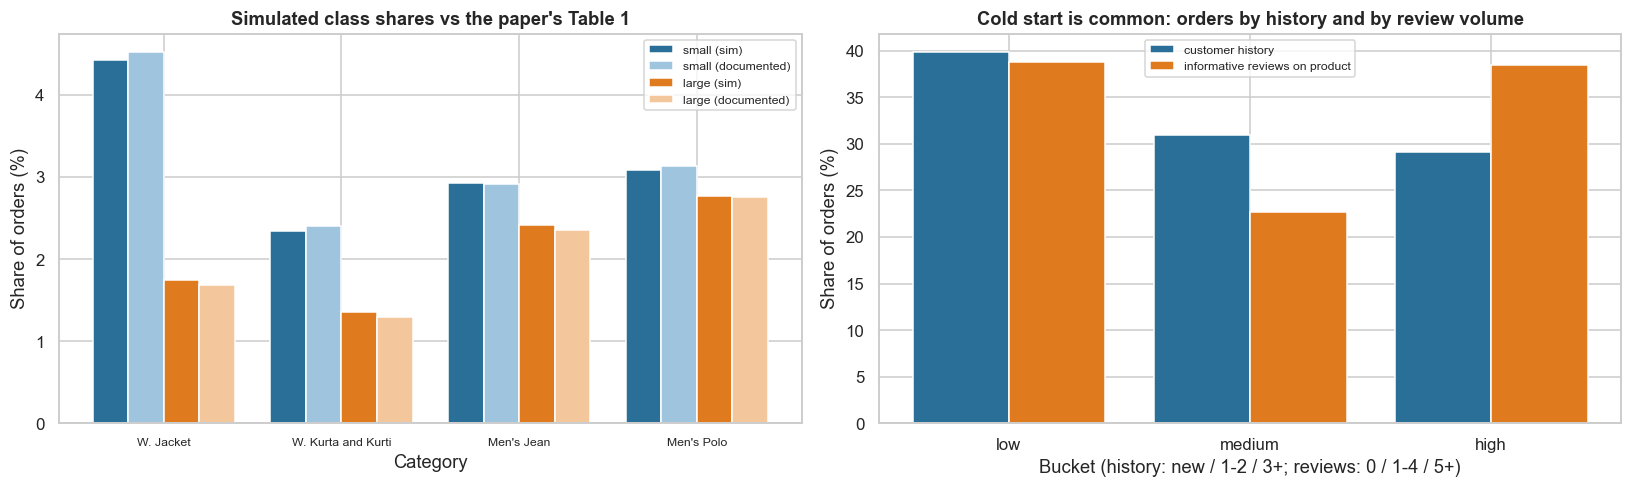

Orders by customer history: {'new customer': 39.8, '1-2 prior orders': 31.0, '3+ prior orders': 29.2}
Orders by informative reviews on the product: {'0 reviews': 38.8, '1-4 reviews': 22.7, '5+ reviews': 38.5}


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
xx = np.arange(4); w = 0.2
axes[0].bar(xx - 1.5 * w, cmp["small (sim)"] * 100, w, label="small (sim)", color="#2a6f97"); axes[0].bar(xx - 0.5 * w, cmp["small (documented)"] * 100, w, label="small (documented)", color="#9ec5dd")
axes[0].bar(xx + 0.5 * w, cmp["large (sim)"] * 100, w, label="large (sim)", color="#e07a1f"); axes[0].bar(xx + 1.5 * w, cmp["large (documented)"] * 100, w, label="large (documented)", color="#f3c79b")
axes[0].set_xticks(xx); axes[0].set_xticklabels([c.replace("Women ", "W. ").replace(" T-shirt", "") for c in CATS], fontsize=8); axes[0].set_xlabel("Category"); axes[0].set_ylabel("Share of orders (%)"); axes[0].set_title("Simulated class shares vs the paper's Table 1"); axes[0].legend(fontsize=8)
pi = P.merge(customers[["customer_id", "pre_orders"]], on="customer_id", how="left")
inf_cnt = reviews[~reviews.generic].groupby("product_id").size().reindex(products.product_id).fillna(0)
nrev = P.product_id.map(inf_cnt).fillna(0); hbin = pd.cut(pi.pre_orders, [-1, 0, 2, 100], labels=["new customer", "1-2 prior orders", "3+ prior orders"]).value_counts(normalize=True).sort_index()
rbin = pd.cut(nrev, [-1, 0, 4, 1e9], labels=["0 reviews", "1-4 reviews", "5+ reviews"]).value_counts(normalize=True).sort_index()
axes[1].bar(np.arange(3) - 0.2, hbin.values * 100, 0.4, color="#2a6f97", label="customer history"); axes[1].bar(np.arange(3) + 0.2, rbin.values * 100, 0.4, color="#e07a1f", label="informative reviews on product")
axes[1].set_xticks(range(3)); axes[1].set_xticklabels(["low", "medium", "high"]); axes[1].set_xlabel("Bucket (history: new / 1-2 / 3+; reviews: 0 / 1-4 / 5+)"); axes[1].set_ylabel("Share of orders (%)"); axes[1].set_title("Cold start is common: orders by history and by review volume"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
print("Orders by customer history:", (hbin * 100).round(1).to_dict()); print("Orders by informative reviews on the product:", (rbin * 100).round(1).to_dict())

**Takeaway:** the shares match the documented ones, and cold start is common. **39.8% of orders come from new customers** with no history, 31.0% from customers with 1 to 2 prior orders and 29.2% from customers with 3 or more. **38.8% of orders are on products with no informative review**, 22.7% on products with 1 to 4 and 38.5% on products with 5 or more. A model that depends only on customer history or on reviews would be blind for a large share of orders.

#### Code

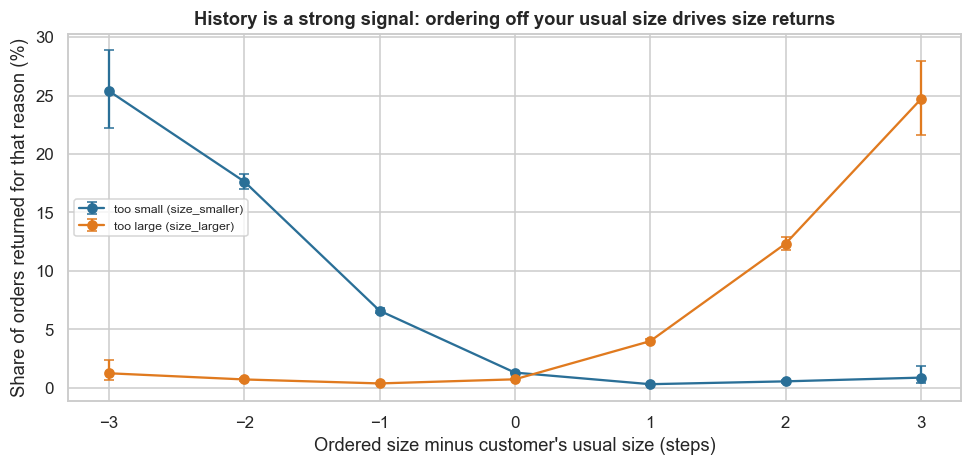

Orders from customers with a usual size: 280,575


class,too large (size_larger),too small (size_smaller),orders
delta,,,
-3,0.0122,0.2538,654
-2,0.0069,0.1764,13677
-1,0.0035,0.0658,59026
0,0.0071,0.0128,133831
1,0.0397,0.0029,58576
2,0.1231,0.0053,14106
3,0.2468,0.0085,705


In [7]:
W = P.merge(customers[["customer_id", "usual_size"]], on="customer_id", how="left"); W = W[W.usual_size.notna()].copy(); W["delta"] = np.clip(np.round(W["size"] - W.usual_size), -3, 3).astype(int)
fig, ax = plt.subplots(figsize=(9, 4.4)); rows = []
for lab, nm, col in ((0, "too small (size_smaller)", "#2a6f97"), (2, "too large (size_larger)", "#e07a1f")):
    r = []
    for dl in range(-3, 4):
        m = W.delta == dl; k = int((W.y[m] == lab).sum()); n = int(m.sum()); lo, hi = proportion_confint(k, n, method="wilson"); r.append((dl, k / n, lo, hi, n))
    r = pd.DataFrame(r, columns=["delta", "rate", "lo", "hi", "n"]); r["class"] = nm; rows.append(r)
    ax.errorbar(r.delta, r.rate * 100, yerr=[(r.rate - r.lo) * 100, (r.hi - r.rate) * 100], marker="o", capsize=3, color=col, label=nm)
ax.set_xlabel("Ordered size minus customer's usual size (steps)"); ax.set_ylabel("Share of orders returned for that reason (%)"); ax.set_title("History is a strong signal: ordering off your usual size drives size returns"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
dtab = pd.concat(rows).pivot(index="delta", columns="class", values="rate"); dtab["orders"] = rows[0].set_index("delta").n; print(f"Orders from customers with a usual size: {len(W):,}"); dtab.round(4)

**Takeaway:** ordering off one's usual size is a strong, near-monotone signal. At the usual size, 1.3% of orders are returned as too small and 0.7% as too large. One step above the usual size, **4.0% are returned as too large** (and 0.3% as too small); two steps above, **12.3%**; three steps, 24.7%. One step below, **6.6% are returned as too small**; two steps, 17.6%; three steps, 25.4%. The ±3 buckets are small (about 650 to 700 orders each), so their rates are rough. This is the signal a new customer lacks.

## 7. Statistical Analysis (core section)

### 7.1 How noisy is the label? Return reason codes as free but imperfect labels

**(a) Why?** The label is "size smaller" or "size larger" if the customer returned the order with that reason, otherwise "fit". Many unhappy customers keep the item, and agents sometimes pick the wrong direction. If the noise is large, every metric we compute has a ceiling. We test whether the class mix differs across categories (chi-square, Cramér's V) and measure the noise using the simulation's hidden truth (not available in real data, where a customer survey or exchange data would be the substitute).

#### Code

In [8]:
ct = pd.crosstab(P.category, P.y); chi2, pchi, dof, _ = stats.chi2_contingency(ct); V = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
tr_sz = P._true_reason.isin(["size_smaller", "size_larger"]); obs_sz = P.y != 1
tp_ = ((P.y == 0) & (P._true_reason == "size_smaller")) | ((P.y == 2) & (P._true_reason == "size_larger"))
rows = [("class mix differs by category: chi-square (df = %d)" % dof, f"{chi2:,.0f}", f"p = {pchi:.2g}; Cramér's V = {V:.3f}"),
        ("true mismatch rate (small or large)", f"{mis.mean():.2%}", "hidden truth"),
        ("share of mismatched orders that were returned", f"{(mis & tr_sz).sum() / mis.sum():.1%}", f"design value {RHO:.0%}"),
        ("'fit' class that is truly mismatched", f"{silent.sum() / (P.y == 1).sum():.1%}", "label noise 1: silent mismatches"),
        ("labelled small/large orders whose reason code is the wrong direction", f"{1 - tp_.sum() / obs_sz.sum():.1%}", "label noise 2: wrong direction code (agent mistake)"),
        ("recall of labels for true mismatches", f"{tp_.sum() / mis.sum():.1%}", "share of true mismatches that carry the correct label")]
pd.DataFrame(rows, columns=["quantity", "value", "note"]).set_index("quantity")

,value,note
quantity,,
class mix differs by category: chi-square (df = 6),"1,648",p = 0; Cramér's V = 0.042
true mismatch rate (small or large),9.84%,hidden truth
share of mismatched orders that were returned,50.0%,design value 50%
'fit' class that is truly mismatched,5.2%,label noise 1: silent mismatches
labelled small/large orders whose reason code is the wrong direction,4.0%,label noise 2: wrong direction code (agent mis...
recall of labels for true mismatches,48.0%,share of true mismatches that carry the correc...


**Observation:** the class mix differs significantly across categories (chi-square 1,648, df 6, p < 1e-300), but the effect is small (Cramér's V = 0.042), so categories differ by a few tenths of a percentage point in mix. The noise is large: only **50.0% of truly mismatched orders were returned**, so **5.2% of the "fit" class is truly mismatched**, **4.0% of size returns have the wrong direction**, and the labels carry the right class for only **48.0% of true mismatches**. Every score below has a ceiling set by this noise. In real data the same check would need exchange records or a fit survey.

### 7.2 Does ordering off your usual size change the odds? (H1)

**(a) Why?** The picture in section 6 suggests the gap between the ordered size and a customer's usual size predicts the return direction. A **logistic regression** with the gap in steps (adjusted for category) turns that into an **odds ratio with a 95% CI**. We fit it for customers who have a usual size and, as a placebo, for the order's size minus the category's average size for customers with no history (a much weaker proxy).

#### Code

In [9]:
W["small"] = (W.y == 0).astype(int); W["large"] = (W.y == 2).astype(int); W["gap"] = W["size"] - W.usual_size; rows = []
for tgt in ("small", "large"):
    m = smf.logit(f"{tgt} ~ gap + C(category)", data=W).fit(disp=0); b = m.params["gap"]; lo, hi = m.conf_int().loc["gap"]
    rows.append((f"{tgt}, customers with a usual size (n = {len(W):,})", np.exp(b), np.exp(lo), np.exp(hi), m.pvalues["gap"]))
Cn = P.merge(customers[["customer_id", "pre_orders"]], on="customer_id"); Cn = Cn[Cn.pre_orders == 0].copy(); Cn["gap"] = Cn["size"] - Cn.groupby("category")["size"].transform("mean")
Cn["small"] = (Cn.y == 0).astype(int); Cn["large"] = (Cn.y == 2).astype(int)
for tgt in ("small", "large"):
    m = smf.logit(f"{tgt} ~ gap + C(category)", data=Cn).fit(disp=0); b = m.params["gap"]; lo, hi = m.conf_int().loc["gap"]
    rows.append((f"{tgt}, new customers: size minus category average (placebo; n = {len(Cn):,})", np.exp(b), np.exp(lo), np.exp(hi), m.pvalues["gap"]))
orr = pd.DataFrame(rows, columns=["model", "odds ratio per size step", "CI low", "CI high", "p"]).set_index("model"); orr.round(4)

,odds ratio per size step,CI low,CI high,p
model,,,,
"small, customers with a usual size (n = 280,575)",0.2389,0.2325,0.2455,0.0000
"large, customers with a usual size (n = 280,575)",3.8941,3.7719,4.0203,0.0000
"small, new customers: size minus category average (placebo; n = 189,629)",0.4808,0.4689,0.4929,0.0000
"large, new customers: size minus category average (placebo; n = 189,629)",2.1670,2.1037,2.2322,0.0000


**Observation:** for customers with a usual size, each step the ordered size is above it **multiplies the odds of "too small" by 0.24** (95% CI 0.23 to 0.25) and **the odds of "too large" by 3.89** (CI 3.77 to 4.02); both p < 1e-100, so we reject H1. The placebo for new customers (ordered size minus the category average) is weaker but still significant: odds ratios 0.48 (CI 0.47 to 0.49) for small and 2.17 (CI 2.10 to 2.23) for large. Ordering far from the category norm is more often a wrong guess; I did not test that explanation. The history signal is worth far more than the category-level proxy.

### 7.3 Review text: does a public-data classifier transfer? (H4)

**(a) Why?** The paper trains a review classifier on public ModCloth data and, separately, on the platform's own labels, and finds the platform-trained models better. Our platform reviews include **Hinglish** ("size chhota hai"), which an English-only public set cannot teach. We train (1) a TF-IDF + logistic classifier on the public labelled set and (2) the same classifier on the platform's own fit tags, using **2-fold cross-fitting** so no review is scored by a model that saw it. We compare macro-F1 on all tagged platform reviews with a bootstrap CI and a **McNemar** test on the same reviews. (Our simulated reviews carry no fit text in 30% of cases, so a perfect score is impossible.)

#### Code

In [10]:
LM = {"small": 0, "fit": 1, "large": 2}
vec_pub = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True); Xp = vec_pub.fit_transform(public.review_text); clf_pub = LogisticRegression(max_iter=1000).fit(Xp, public.label.map(LM))
vec_pl = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True); Xr = vec_pl.fit_transform(reviews.review_text); Xr_pub = vec_pub.transform(reviews.review_text)
tag_idx = np.where(reviews.fit_tag.values != "")[0]; ytag = pd.Series(reviews.fit_tag.values[tag_idx]).map({"small": 0, "ok": 1, "large": 2}).values; fold = RNG.integers(0, 2, len(tag_idx))
m_f = [LogisticRegression(max_iter=1000).fit(Xr[tag_idx[fold == k]], ytag[fold == k]) for k in (0, 1)]
PR_PLAT = (m_f[0].predict_proba(Xr) + m_f[1].predict_proba(Xr)) / 2
for k in (0, 1):
    sel = tag_idx[fold == k]; PR_PLAT[sel] = m_f[1 - k].predict_proba(Xr[sel])
PR_PUB = clf_pub.predict_proba(Xr_pub)
pred_pub = PR_PUB[tag_idx].argmax(1); pred_pl = PR_PLAT[tag_idx].argmax(1)
hindi = reviews.review_text.str.contains(r"chhota|chhoti|bada|badi|dheela|sahi|badhiya|aaya|aayi|lena|hai", regex=True).values[tag_idx]
def mf1_(y, p): return f1_score(y, p, average="macro")
bi = [RNG.integers(0, len(tag_idx), len(tag_idx)) for _ in range(300)]; rows = []
for nm, pr in (("public-trained (transfer)", pred_pub), ("platform-trained (fine-tuned)", pred_pl)):
    bs = [mf1_(ytag[i], pr[i]) for i in bi]; rows.append((nm, len(tag_idx), mf1_(ytag, pr), np.percentile(bs, 2.5), np.percentile(bs, 97.5), mf1_(ytag[~hindi], pr[~hindi]), mf1_(ytag[hindi], pr[hindi])))
txt = pd.DataFrame(rows, columns=["classifier", "tagged reviews", "macro-F1", "CI low", "CI high", "macro-F1 English-style", "macro-F1 Hinglish-style"]).set_index("classifier")
a_, b_ = pred_pl == ytag, pred_pub == ytag; mc = mcnemar([[int((a_ & b_).sum()), int((a_ & ~b_).sum())], [int((~a_ & b_).sum()), int((~a_ & ~b_).sum())]], exact=False, correction=True)
print(f"McNemar (platform-trained vs public-trained correct/incorrect): only platform right {int((a_ & ~b_).sum())}, only public right {int((~a_ & b_).sum())}, p = {mc.pvalue:.2g} | Hinglish-style share of tagged reviews: {hindi.mean():.1%}")
txt.round(4)

McNemar (platform-trained vs public-trained correct/incorrect): only platform right 366, only public right 31, p = 4.6e-63 | Hinglish-style share of tagged reviews: 21.0%


,tagged reviews,macro-F1,CI low,CI high,macro-F1 English-style,macro-F1 Hinglish-style
classifier,,,,,,
public-trained (transfer),3724,0.7244,0.7075,0.7418,0.7891,0.4017
platform-trained (fine-tuned),3724,0.8375,0.8248,0.8506,0.7883,1.0000


**Observation:** a classifier trained only on the public English labelled set reaches macro-F1 **0.724** (95% CI 0.708 to 0.742) on the platform's tagged reviews, against **0.838** (CI 0.825 to 0.851) for the platform-trained one. They agree on English-style text (0.789 vs 0.788) and differ on Hinglish-style text (**0.40 vs 1.00**), which is 21.0% of tagged reviews. McNemar: the platform model alone is right on 366 reviews and the public model alone on 31 (p = 4.6e-63), so we reject H4. The 1.00 on Hinglish is an artefact of the simulation: the keyword that defines "Hinglish-style" appears only in reviews that state the fit in Hindi, and our templates are clean. Real Hinglish text is messier, so the gap is directionally right but exaggerated.

### 7.4 Does the product-level review score line up with real returns?

**(a) Why?** The model will use, per product, the average predicted "small" and "large" probability over its informative reviews. Before trusting it, we check against the returns themselves: for products with at least 30 orders in the **training period** (days 0–119), the correlation (Spearman) between the review score (mean P(large) − mean P(small)) and the product's actual large-minus-small return rate. We also use the simulation's hidden truth to show how the quality of the score depends on review volume (the correlation with the true "runs large" offset).

#### Code

In [11]:
def agg_reviews(pr):
    d = pd.DataFrame({"product_id": reviews.product_id.values, "ps": pr[:, 0], "pl": pr[:, 2], "inf": ~reviews.generic.values}); n_all = d.groupby("product_id").size().rename("rv_n")
    g_ = d[d["inf"]].groupby("product_id").agg(rv_n_inf=("ps", "size"), rv_ps=("ps", "mean"), rv_pl=("pl", "mean")); out = pd.concat([n_all, g_], axis=1).reindex(products.product_id).fillna(0)
    out["rv_net"] = out.rv_pl - out.rv_ps; out["rv_net_shr"] = out.rv_net * out.rv_n_inf / (out.rv_n_inf + 3); return out
RV_PLAT = agg_reviews(PR_PLAT); RV_PUB = agg_reviews(PR_PUB)
trn = P[P.day < 120]; pp = trn.groupby("product_id").agg(n=("y", "size"), small=("y", lambda s: (s == 0).mean()), large=("y", lambda s: (s == 2).mean())); pp["net_ret"] = pp.large - pp.small
pp = pp.join(RV_PLAT[["rv_n_inf", "rv_net"]]).join(products.set_index("product_id")._runs); sel = pp[(pp.n >= 30) & (pp.rv_n_inf >= 3)]
rho_ret = stats.spearmanr(sel.rv_net, sel.net_ret); boot = [stats.spearmanr(sel.rv_net.values[i], sel.net_ret.values[i])[0] for i in (RNG.integers(0, len(sel), len(sel)) for _ in range(300))]
print(f"Products with ≥ 30 training orders and ≥ 3 informative reviews: {len(sel):,} | Spearman(review score, actual large−small return rate) = {rho_ret[0]:+.3f} (95% CI {np.percentile(boot, 2.5):+.3f} to {np.percentile(boot, 97.5):+.3f}), p = {rho_ret[1]:.2g}")
pe = pp[pp.index.isin(products.product_id[products.launch_day < 0])]; rows = []
for lo_, hi_ in ((1, 2), (3, 5), (6, 10), (11, 20), (21, 10 ** 6)):
    m = (pe.rv_n_inf >= lo_) & (pe.rv_n_inf <= hi_); rows.append((f"{lo_}-{hi_ if hi_ < 10 ** 5 else '+'}", int(m.sum()), stats.pearsonr(pe.rv_net[m], pe._runs[m])[0]))
print("\nCorrelation of review score with the HIDDEN true product offset, by informative reviews per product:"); pd.DataFrame(rows, columns=["informative reviews", "products", "corr with hidden truth"]).set_index("informative reviews").round(3)

Products with ≥ 30 training orders and ≥ 3 informative reviews: 1,205 | Spearman(review score, actual large−small return rate) = +0.567 (95% CI +0.526 to +0.609), p = 1.9e-103

Correlation of review score with the HIDDEN true product offset, by informative reviews per product:


,products,corr with hidden truth
informative reviews,,
1-2,779,0.4410
3-5,860,0.6540
6-10,945,0.7770
11-20,916,0.8590
21-+,571,0.9290


**Observation:** for the 1,205 products with at least 30 training orders and 3 informative reviews, the review score (mean P(large) − mean P(small)) has a **Spearman correlation of +0.567** (95% CI +0.526 to +0.609) with the product's actual large-minus-small return rate. Using the hidden truth, the score tracks the true product offset better as reviews accumulate: correlation **0.44** with 1 to 2 informative reviews, 0.65 with 3 to 5, 0.78 with 6 to 10, 0.86 with 11 to 20 and **0.93** with 21 or more. So the score is useful but noisy for products with few reviews, which is why the model also sees the review count.

### 7.5 Model comparison: does adding reviews help? (H2)

**(a) Why?** We follow the paper's setup but add uncertainty. **Time-based split:** train on orders from days 0–119, validate on days 120–149 (used only to calibrate and to choose the tip threshold), test on days 150–179. Rows are weighted to balance the three classes (the paper re-samples). Models, all at library defaults with **no tuning**:

| Model | Features |
|---|---|
| Prior | Always "fit" (the floor for macro-F1) |
| L-reviews | Reviews only (plus category), as in the paper's "Only Reviews" |
| L0 / G0 | Customer + product + size (no reviews): logistic / gradient boosting |
| L1 / G1 | L0 / G0 + review features from the platform-trained classifier |
| G2 | G0 + review features from the public-trained classifier (transfer only) |

**Macro-F1** (argmax of the class-balanced probabilities) matches the paper's metric; **mean average precision (mAP)** over small and large does not depend on a cut-off. 95% CIs are percentile bootstraps over test orders (300 resamples, the same resamples for every model so comparisons are **paired**).

#### Code

In [12]:
F = P[["order_id", "customer_id", "product_id", "category", "day", "cat", "size", "y"]].copy()
F = F.join(customers.set_index("customer_id")[["age_band", "city_tier", "pre_orders", "pre_small_returns", "pre_large_returns", "usual_size"]], on="customer_id")
F = F.join(products.set_index("product_id")[["brand", "fabric", "price_inr", "launch_day", "avg_rating_snapshot"]], on="product_id")
trm = F.day < 120; cat_mean = F[trm].groupby("cat")["size"].mean()
F["pre_return_rate"] = (F.pre_small_returns + F.pre_large_returns) / np.maximum(F.pre_orders, 1); F["has_usual"] = F.usual_size.notna().astype(int); F["size_minus_usual"] = (F["size"] - F.usual_size).fillna(0); F["usual_filled"] = F.usual_size.fillna(F.cat.map(cat_mean))
F["size_vs_cat"] = F["size"] - F.cat.map(cat_mean); F["logp"] = np.log(F.price_inr); F["new_product"] = (F.launch_day >= 0).astype(int); F["age_code"] = F.age_band.astype("category").cat.codes
F["brand_code"] = F.brand.fillna("unknown").astype("category").cat.codes; F["fabric_code"] = F.fabric.astype("category").cat.codes; F = F.rename(columns={"avg_rating_snapshot": "avg_rating"})
NUM_C = ["city_tier", "pre_orders", "pre_small_returns", "pre_large_returns", "pre_return_rate", "has_usual", "size_minus_usual", "usual_filled"]; NUM_S = ["size", "size_vs_cat"]; NUM_P = ["logp", "avg_rating", "new_product"]
CAT_ = ["cat", "brand_code", "fabric_code", "age_code"]; NUM_R = ["rv_n", "rv_n_inf", "rv_ps", "rv_pl", "rv_net", "rv_net_shr"]
def with_rev(RV): return F.join(RV[NUM_R], on="product_id")
FP, FB = with_rev(RV_PLAT), with_rev(RV_PUB)
iva = ((F.day >= 120) & (F.day < 150)).values; ite = (F.day >= 150).values; itr = trm.values; y = F.y.values
def design(Fd, num, cats):
    X = Fd[num].astype(float); X = (X - X[itr].mean()) / X[itr].std().replace(0, 1)
    return pd.concat([X] + [pd.get_dummies(Fd[c].astype(str), prefix=c, dtype=float) for c in cats], axis=1)
XL = design(FP, NUM_C + NUM_S + NUM_P + NUM_R, CAT_); revcols = NUM_R; nonrev = [c for c in XL.columns if c not in revcols]; onlyrev = revcols + [c for c in XL.columns if c.startswith("cat_")]
def fit_lr(cols):
    m = LogisticRegression(max_iter=500, class_weight="balanced").fit(XL.loc[itr, cols], y[itr]); return m.predict_proba(XL.loc[iva, cols]), m.predict_proba(XL.loc[ite, cols])
hgb_cols0 = NUM_C + NUM_S + NUM_P + CAT_; hgb_cols1 = hgb_cols0 + NUM_R
def fit_gb(Fd, cols):
    mask = [c in CAT_ for c in cols]; m = HistGradientBoostingClassifier(categorical_features=mask, random_state=SEED).fit(Fd.loc[itr, cols], y[itr], sample_weight=compute_sample_weight("balanced", y[itr]))
    return m, m.predict_proba(Fd.loc[iva, cols]), m.predict_proba(Fd.loc[ite, cols])
t0 = time.time(); PV, PT = {}, {}
PV["L-reviews only"], PT["L-reviews only"] = fit_lr(onlyrev); PV["L0 logistic, no reviews"], PT["L0 logistic, no reviews"] = fit_lr(nonrev); PV["L1 logistic + reviews"], PT["L1 logistic + reviews"] = fit_lr(list(XL.columns))
_, PV["G0 boosting, no reviews"], PT["G0 boosting, no reviews"] = fit_gb(FP, hgb_cols0); mG1, PV["G1 boosting + reviews"], PT["G1 boosting + reviews"] = fit_gb(FP, hgb_cols1); _, PV["G2 boosting + public-trained reviews"], PT["G2 boosting + public-trained reviews"] = fit_gb(FB, hgb_cols1)
yt = y[ite]; print(f"Train {itr.sum():,} | validation {iva.sum():,} | test {ite.sum():,} orders (test: small {np.mean(yt == 0):.2%}, large {np.mean(yt == 2):.2%}) | models fitted in {time.time() - t0:.0f}s")
def mf1(yy, pp): cm = np.bincount(3 * yy + pp, minlength=9).reshape(3, 3); return (2 * np.diag(cm) / np.maximum(cm.sum(0) + cm.sum(1), 1)).mean()
def mAP(yy, p): return (average_precision_score(yy == 0, p[:, 0]) + average_precision_score(yy == 2, p[:, 2])) / 2
B = 200; BI = [RNG.integers(0, len(yt), len(yt)) for _ in range(B)]; BS = {}; rows = []
base_f1 = mf1(yt, np.ones(len(yt), int))
for k, p in PT.items():
    pl = p.argmax(1); BS[k] = np.array([[mf1(yt[i], pl[i]), mAP(yt[i], p[i])] for i in BI])
    rows.append((k, mf1(yt, pl), *np.percentile(BS[k][:, 0], [2.5, 97.5]), mAP(yt, p), *np.percentile(BS[k][:, 1], [2.5, 97.5]), average_precision_score(yt == 0, p[:, 0]), average_precision_score(yt == 2, p[:, 2])))
res = pd.DataFrame(rows, columns=["model", "macro-F1", "F1 CI low", "F1 CI high", "mAP", "mAP CI low", "mAP CI high", "AP small", "AP large"]).set_index("model")
print(f"Prior (always 'fit') macro-F1 = {base_f1:.4f}; random-ranking AP = class share (small {np.mean(yt == 0):.4f}, large {np.mean(yt == 2):.4f})"); res.round(4)

Train 299,301 | validation 88,211 | test 88,536 orders (test: small 3.05%, large 1.93%) | models fitted in 2868s


Prior (always 'fit') macro-F1 = 0.3248; random-ranking AP = class share (small 0.0305, large 0.0193)


,macro-F1,F1 CI low,F1 CI high,mAP,mAP CI low,mAP CI high,AP small,AP large
model,,,,,,,,
L-reviews only,0.2137,0.2114,0.2158,0.0463,0.0441,0.0495,0.0519,0.0407
"L0 logistic, no reviews",0.3228,0.3197,0.3265,0.1556,0.1462,0.1640,0.1805,0.1307
L1 logistic + reviews,0.3283,0.3249,0.3313,0.1640,0.1552,0.1736,0.1849,0.1432
"G0 boosting, no reviews",0.3512,0.3479,0.3546,0.1670,0.1587,0.1769,0.1958,0.1381
G1 boosting + reviews,0.3557,0.3524,0.3590,0.1752,0.1657,0.1835,0.2020,0.1484
G2 boosting + public-trained reviews,0.3581,0.3549,0.3616,0.1715,0.1630,0.1804,0.1996,0.1433


**Observation:** the always-"fit" prior scores macro-F1 **0.325**. **Macro-F1 barely separates the models**: logistic regression without reviews is at 0.323 (CI 0.320 to 0.327), no better than the prior, because the class-balanced argmax predicts many false small and large. Boosting is higher: 0.351 without reviews (CI 0.348 to 0.355) and **0.356 with reviews** (0.352 to 0.359). The ranking metric shows more: mAP is 0.156 (logistic) and 0.167 (boosting) without reviews, and **0.164 and 0.175 with reviews**; random ranking would give about 0.025. Reviews alone score mAP 0.046 and macro-F1 0.214, far below the baseline, matching the paper's finding that review-only models lose. The public-trained review variant (G2) has mAP 0.172 and macro-F1 0.358. The paper's baseline macro-F1 (35.6 to 38.3) is on different data and is not comparable.

#### Paired comparisons (Holm-corrected)

In [13]:
def pcmp(a, b, j):
    d = BS[a][:, j] - BS[b][:, j]; est = (mAP(yt, PT[a]) - mAP(yt, PT[b])) if j == 1 else (mf1(yt, PT[a].argmax(1)) - mf1(yt, PT[b].argmax(1)))
    p = 2 * (1 + min((d <= 0).sum(), (d >= 0).sum())) / (B + 1); return est, *np.percentile(d, [2.5, 97.5]), min(p, 1.0)
pairs = [("L1 logistic + reviews", "L0 logistic, no reviews", "reviews added (logistic)"), ("G1 boosting + reviews", "G0 boosting, no reviews", "reviews added (boosting)"), ("G0 boosting, no reviews", "L0 logistic, no reviews", "boosting vs logistic (no reviews)"),
         ("G1 boosting + reviews", "G2 boosting + public-trained reviews", "platform-trained vs public-trained reviews")]
rows = []
for a, b, lab in pairs:
    e1 = pcmp(a, b, 1); e0 = pcmp(a, b, 0); rows.append((lab, e1[0], e1[1], e1[2], e1[3], e0[0], e0[1], e0[2], e0[3]))
pc = pd.DataFrame(rows, columns=["comparison (first minus second)", "Δ mAP", "CI low", "CI high", "p (boot)", "Δ macro-F1", "F1 CI low", "F1 CI high", "p F1 (boot)"]).set_index("comparison (first minus second)")
pc["p_holm (mAP)"] = multipletests(pc["p (boot)"], method="holm")[1]; pc["p_holm (F1)"] = multipletests(pc["p F1 (boot)"], method="holm")[1]; pc.round(4)

,Δ mAP,CI low,CI high,p (boot),Δ macro-F1,F1 CI low,F1 CI high,p F1 (boot),p_holm (mAP),p_holm (F1)
comparison (first minus second),,,,,,,,,,
reviews added (logistic),0.0084,0.0055,0.0109,0.0100,0.0054,0.0040,0.0066,0.0100,0.0398,0.0398
reviews added (boosting),0.0082,0.0037,0.0114,0.0100,0.0045,0.0032,0.0056,0.0100,0.0398,0.0398
boosting vs logistic (no reviews),0.0113,0.0059,0.0178,0.0100,0.0283,0.0268,0.0299,0.0100,0.0398,0.0398
platform-trained vs public-trained reviews,0.0037,0.0004,0.0070,0.0498,-0.0024,-0.0036,-0.0012,0.0100,0.0498,0.0398


**Observation:** **adding reviews raises mAP by +0.0084 for logistic regression** (CI +0.0055 to +0.0109) and **by +0.0082 for boosting** (CI +0.0037 to +0.0114), with macro-F1 gains of +0.0054 and +0.0045; the Holm-adjusted p is 0.040 for both (the bootstrap has 200 resamples, so the smallest possible p is 0.01 before correction). We reject H2, but the gain is small: under 5% relative in mAP. **Boosting beats logistic regression** by +0.011 mAP and +0.028 macro-F1. The platform-trained review features beat the public-trained ones by +0.0037 mAP (CI +0.0004 to +0.0070, Holm p = 0.050) but have a **lower macro-F1 by 0.0024** (CI −0.0036 to −0.0012), so the transfer comparison is mixed and borderline.

### 7.6 Cold start: who gains from reviews? (H3)

**(a) Why?** The paper's motivation for text is the customer with no history. We measure the gain in mAP from reviews (G1 minus G0) separately for **new customers vs customers with history** and for products with **0, 1 to 4 and 5+ informative reviews**, with bootstrap CIs (resampling within each segment). The difference in gains between new and returning customers has its own CI (independent resamples). We also give the gain per category with Holm-corrected p-values.

#### Code

Difference in gain, new minus returning customers: -0.0058 (95% CI -0.0131 to +0.0020), p = 0.199


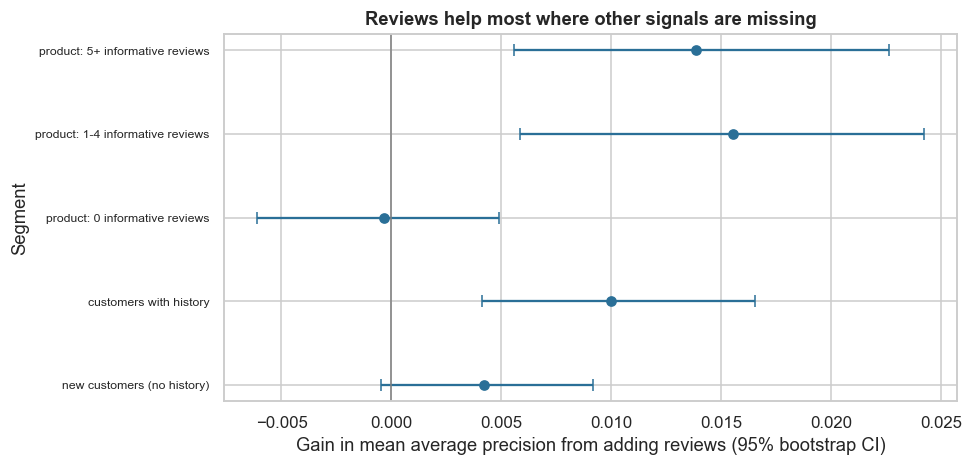

                                 gain in mAP (G1 − G0)  CI low CI high  orders mAP without reviews size-return share
new customers (no history)                      0.0042 -0.0005  0.0092   35338              0.1154            0.0490
customers with history                          0.0100  0.0041  0.0165   53198              0.1964            0.0503
product: 0 informative reviews                 -0.0003 -0.0061  0.0049   40008              0.1659            0.0498
product: 1-4 informative reviews                0.0155  0.0058  0.0242   17954              0.1548            0.0501
product: 5+ informative reviews                 0.0138  0.0056  0.0226   30574              0.1764            0.0496


,orders,size-return share,mAP without reviews,gain,CI low,CI high,p,p_holm
category,,,,,,,,
Women Jacket,14403,0.0644,0.1822,0.0072,-0.0040,0.0183,0.2119,0.4238
Women Kurta and Kurti,34267,0.0377,0.1774,0.0009,-0.0068,0.0086,0.7285,0.7285
Men's Jean,22302,0.0525,0.1531,0.0080,0.0002,0.0150,0.0662,0.1987
Men's Polo T-shirt,17564,0.0580,0.1620,0.0147,0.0063,0.0243,0.0132,0.0530


In [14]:
Te = FP[ite].reset_index(drop=True); a1, a0 = PT["G1 boosting + reviews"], PT["G0 boosting, no reviews"]
def seg_gain(mask, nb=200):
    idx = np.where(mask)[0]; d = []
    for _ in range(nb):
        i = RNG.choice(idx, len(idx)); d.append(mAP(yt[i], a1[i]) - mAP(yt[i], a0[i]))
    est = mAP(yt[idx], a1[idx]) - mAP(yt[idx], a0[idx]); return est, np.percentile(d, 2.5), np.percentile(d, 97.5), np.array(d), len(idx), mAP(yt[idx], a0[idx]), (yt[idx] != 1).mean()
segs = {"new customers (no history)": (Te.pre_orders == 0).values, "customers with history": (Te.pre_orders > 0).values, "product: 0 informative reviews": (Te.rv_n_inf == 0).values,
        "product: 1-4 informative reviews": ((Te.rv_n_inf >= 1) & (Te.rv_n_inf <= 4)).values, "product: 5+ informative reviews": (Te.rv_n_inf >= 5).values}
SG = {k: seg_gain(m) for k, m in segs.items()}
did = SG["new customers (no history)"][3] - SG["customers with history"][3]; pdid = 2 * (1 + min((did <= 0).sum(), (did >= 0).sum())) / (len(did) + 1)
print(f"Difference in gain, new minus returning customers: {SG['new customers (no history)'][0] - SG['customers with history'][0]:+.4f} (95% CI {np.percentile(did, 2.5):+.4f} to {np.percentile(did, 97.5):+.4f}), p = {min(pdid, 1):.3g}")
sg = pd.DataFrame({k: dict(zip(["gain in mAP (G1 − G0)", "CI low", "CI high", "_", "orders", "mAP without reviews", "size-return share"], v)) for k, v in SG.items()}).T.drop(columns="_"); sg["orders"] = sg.orders.astype(int)
fig, ax = plt.subplots(figsize=(9, 4.4)); yy = np.arange(len(sg)); ax.errorbar(sg["gain in mAP (G1 − G0)"], yy, xerr=[sg["gain in mAP (G1 − G0)"] - sg["CI low"], sg["CI high"] - sg["gain in mAP (G1 − G0)"]], fmt="o", color="#2a6f97", capsize=4)
ax.axvline(0, color="grey", lw=1); ax.set_yticks(yy); ax.set_yticklabels(sg.index, fontsize=8); ax.set_xlabel("Gain in mean average precision from adding reviews (95% bootstrap CI)"); ax.set_ylabel("Segment"); ax.set_title("Reviews help most where other signals are missing")
plt.tight_layout(); plt.show()
rows = []
for c in CATS:
    m = (Te.category == c).values; r = seg_gain(m, 150); pv = 2 * (1 + min((r[3] <= 0).sum(), (r[3] >= 0).sum())) / (len(r[3]) + 1); rows.append((c, r[4], r[6], r[5], r[0], r[1], r[2], min(pv, 1)))
pcat = pd.DataFrame(rows, columns=["category", "orders", "size-return share", "mAP without reviews", "gain", "CI low", "CI high", "p"]).set_index("category"); pcat["p_holm"] = multipletests(pcat.p, method="holm")[1]
print(sg.round(4).to_string()); pcat.round(4)

**Takeaway:** **gain by customer type:** +0.0042 mAP for new customers (CI −0.0005 to +0.0092, includes zero) and +0.0100 for customers with history (CI +0.0041 to +0.0165). The difference (new minus returning) is −0.0058 (CI −0.0131 to +0.0020, p = 0.20), so we cannot reject H3 for customer type; on this data the paper's cold-start motivation is **not confirmed**. **Gain by review volume** is clear: **−0.0003** for products with 0 informative reviews (CI −0.0061 to +0.0049), **+0.0155** for 1 to 4 (CI +0.0058 to +0.0242) and **+0.0138** for 5+ (CI +0.0056 to +0.0226). Reviews cannot help a product that has none, which is the new-product cold start. By category only Men's Polo shows a gain near significance (+0.0147, Holm p = 0.053); jacket, kurta and jean gains are not distinguishable from zero after Holm.

### 7.7 Calibration and lift of the tip score (H5)

**(a) Why?** Class-balanced training makes the probabilities too high for the minority classes, so we **recalibrate** on the validation period (Platt scaling per class, one-vs-rest) before using a threshold. We then check on the test period that the calibrated probability matches the observed rate (reliability by decile of score, and expected calibration error) and how much better flagged orders are than the base rate (**lift**; a z-test for the proportion of flagged orders that really have the predicted size problem, with a Wilson CI).

#### Code

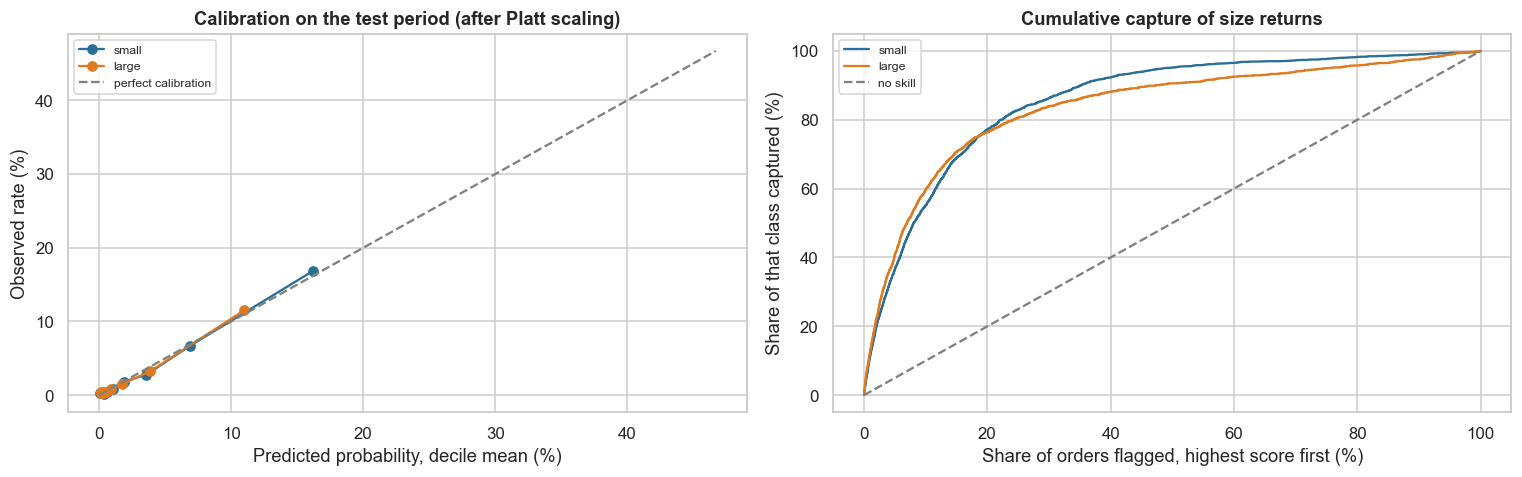

class    ECE  top-decile lift  top-decile observed rate  base rate
small 0.0026           5.5190                    0.1681     0.0305
large 0.0022           5.9694                    0.1154     0.0193


,score cut-off,orders flagged,precision (right direction),CI low,CI high,base rate,lift,p (one-sided z)
flagged share,,,,,,,,
top 1%,0.2558,886,0.3612,0.3302,0.3933,0.0283,12.7428,0.0000
top 2%,0.2167,1771,0.3100,0.2889,0.3319,0.0278,11.1373,0.0000
top 5%,0.1659,4427,0.2431,0.2306,0.2559,0.0276,8.8050,0.0000
top 10%,0.1232,8854,0.1973,0.1892,0.2057,0.0272,7.2612,0.0000
top 20%,0.0769,17708,0.1461,0.1410,0.1514,0.0266,5.4934,0.0000


In [15]:
def logit_(p): p = np.clip(p, 1e-6, 1 - 1e-6); return np.log(p / (1 - p))[:, None]
pv, pt_ = PV["G1 boosting + reviews"], PT["G1 boosting + reviews"]; yv = y[iva]; CAL = np.zeros_like(pt_); CALV = np.zeros_like(pv)
for k in (0, 2):
    pl = LogisticRegression(C=1e6).fit(logit_(pv[:, k]), (yv == k).astype(int)); CAL[:, k] = pl.predict_proba(logit_(pt_[:, k]))[:, 1]; CALV[:, k] = pl.predict_proba(logit_(pv[:, k]))[:, 1]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5)); rows = []
for k, nm, col in ((0, "small", "#2a6f97"), (2, "large", "#e07a1f")):
    dec = pd.qcut(pd.Series(CAL[:, k]).rank(method="first"), 10, labels=False); g = pd.DataFrame({"p": CAL[:, k], "o": (yt == k).astype(int), "d": dec}).groupby("d").agg(p=("p", "mean"), o=("o", "mean"), n=("o", "size"))
    axes[0].plot(g.p * 100, g.o * 100, "o-", color=col, label=nm); ece = (g.n * (g.p - g.o).abs()).sum() / g.n.sum(); rows.append((nm, ece, g.o.iloc[-1] / np.mean(yt == k), g.o.iloc[-1], np.mean(yt == k)))
    order = np.argsort(-CAL[:, k]); cum = np.cumsum(yt[order] == k) / (yt == k).sum(); axes[1].plot(np.arange(1, len(yt) + 1) / len(yt) * 100, cum * 100, color=col, label=nm)
mx = max(CAL[:, 0].max(), CAL[:, 2].max()) * 100; axes[0].plot([0, mx], [0, mx], "--", color="grey", label="perfect calibration"); axes[0].set_xlabel("Predicted probability, decile mean (%)"); axes[0].set_ylabel("Observed rate (%)"); axes[0].set_title("Calibration on the test period (after Platt scaling)"); axes[0].legend(fontsize=8)
axes[1].plot([0, 100], [0, 100], "--", color="grey", label="no skill"); axes[1].set_xlabel("Share of orders flagged, highest score first (%)"); axes[1].set_ylabel("Share of that class captured (%)"); axes[1].set_title("Cumulative capture of size returns"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
sc = np.maximum(CAL[:, 0], CAL[:, 2]); dirn_ = np.where(CAL[:, 0] >= CAL[:, 2], 0, 2); rows2 = []
for q in (0.01, 0.02, 0.05, 0.10, 0.20):
    thr = np.quantile(sc, 1 - q); fl = sc >= thr; hit = (yt[fl] == dirn_[fl]); lo, hi = proportion_confint(hit.sum(), fl.sum(), method="wilson"); base = np.mean(np.where(dirn_[fl] == 0, np.mean(yt == 0), np.mean(yt == 2)))
    z = (hit.mean() - base) / np.sqrt(base * (1 - base) / fl.sum()); rows2.append((f"top {q:.0%}", thr, int(fl.sum()), hit.mean(), lo, hi, base, hit.mean() / base, stats.norm.sf(z)))
print(pd.DataFrame(rows, columns=["class", "ECE", "top-decile lift", "top-decile observed rate", "base rate"]).round(4).to_string(index=False))
lift = pd.DataFrame(rows2, columns=["flagged share", "score cut-off", "orders flagged", "precision (right direction)", "CI low", "CI high", "base rate", "lift", "p (one-sided z)"]).set_index("flagged share"); lift.round(4)

**Takeaway:** probabilities are well calibrated after Platt scaling on the validation period (ECE 0.0026 for small and 0.0022 for large), and the top decile of the score has a **lift of 5.5 for small and 6.0 for large** (observed rates 16.8% and 11.5% against base rates of 3.1% and 1.9%). Among the top 1% of orders, **36.1%** (CI 33.0% to 39.3%) have the predicted problem, a lift of 12.7; the top 5% have 24.3% (lift 8.8), the top 10% 19.7% and the top 20% 14.6% (lift 5.5). All are far above the base rate (one-sided p < 1e-4), so we reject H5. The more orders we flag, the lower the precision, which is why the tip cut-off is a business choice.

### 7.8 What would an A/B test need? Sample size for a product-page tip

**(a) Why?** A tip changes behaviour only on the orders where it is shown, so we analyse the **triggered** orders (flagged ones) and compare with a randomised control that would have been flagged too. We use the flagged share from 7.7 (top 5% by score on the test period) and the observed size-return rate among them (the predicted direction's rate) as the control rate. For a relative reduction of 10%, 20% and 30% in that rate (80% power, α = 0.05, two-sided), we compute the **flagged orders per arm**, the **total orders** needed to collect them, and the number of **customers** if each customer contributes about 1.4 orders (design effect from an intra-customer correlation of 0.05). For comparison we also show the (much larger) sample if we ignored triggering and analysed all orders.

#### Code

In [16]:
fl5 = sc >= np.quantile(sc, 0.95); p_ctrl = np.mean(yt[fl5] == dirn_[fl5]); share = fl5.mean(); p_all = np.mean(yt != 1); rows = []
def n_arm(p0, p1): return int(np.ceil((1.96 + 0.84) ** 2 * (p0 * (1 - p0) + p1 * (1 - p1)) / (p0 - p1) ** 2))
for rel in (0.10, 0.20, 0.30):
    n_trig = n_arm(p_ctrl, p_ctrl * (1 - rel)); deff = 1 + 0.4 * 0.05; p_diluted = p_all - share * p_ctrl * rel; n_all = n_arm(p_all, p_all - share * p_ctrl * rel)
    rows.append((f"-{rel:.0%}", p_ctrl, n_trig, int(n_trig / share), int(np.ceil(n_trig * deff / 1.4)), n_all))
ab = pd.DataFrame(rows, columns=["relative drop in the flagged rate", "control rate (flagged)", "flagged orders per arm", "total orders per arm to collect them", "customers per arm", "orders per arm if all orders analysed"]).set_index("relative drop in the flagged rate")
print(f"Flagged share {share:.1%}; control size-return rate among flagged (predicted direction) = {p_ctrl:.1%}; all-order size-return rate = {p_all:.1%}"); ab.round(4)

Flagged share 5.0%; control size-return rate among flagged (predicted direction) = 24.3%; all-order size-return rate = 5.0%


,control rate (flagged),flagged orders per arm,total orders per arm to collect them,customers per arm,orders per arm if all orders analysed
relative drop in the flagged rate,,,,,
-10%,0.2431,4710,94195,3432,496415
-20%,0.2431,1131,22618,825,122646
-30%,0.2431,480,9599,350,53860


**Observation:** flagging the top 5% of orders, the control rate of the predicted size problem is **24.3%**. To detect a **10% relative drop** needs 4,710 flagged orders per arm (94,195 orders, 3,432 customers); **20%** needs 1,131 (22,618 orders, 825 customers); **30%** needs 480 (9,599 orders, 350 customers). Ignoring triggering and analysing all orders would need 496,415, 122,646 and 53,860 orders per arm. Analysing only triggered orders, with a control group that would also have been flagged, cuts the sample needed by a factor of about five.

## 8. ML Section — what we built and what is beyond it

- **What drives the model?** We permute groups of features together on the validation period and measure the drop in mAP (higher drop = more important).
- **No tuning:** both model families use library defaults; the review classifier is a TF-IDF logistic model, a stand-in for the paper's BERT-family encoders.

#### Code

In [17]:
Xv = FP.loc[iva, hgb_cols1].reset_index(drop=True); yvv = y[iva]; base = mAP(yvv, mG1.predict_proba(Xv)); sub = RNG.choice(len(Xv), 30000, replace=False); Xs, ys = Xv.iloc[sub].reset_index(drop=True), yvv[sub]; base_s = mAP(ys, mG1.predict_proba(Xs))
groups = {"customer history and size gap": ["pre_orders", "pre_small_returns", "pre_large_returns", "pre_return_rate", "has_usual", "size_minus_usual", "usual_filled"], "ordered size": ["size", "size_vs_cat"], "brand and fabric": ["brand_code", "fabric_code"],
          "review features": NUM_R, "category, price, rating": ["cat", "logp", "avg_rating", "new_product"], "customer demographics": ["city_tier", "age_code"]}
rows = []
for g_, cols in groups.items():
    d = []
    for _ in range(3):
        Xp_ = Xs.copy(); perm = RNG.permutation(len(Xp_)); Xp_[cols] = Xs[cols].values[perm]; d.append(base_s - mAP(ys, mG1.predict_proba(Xp_)))
    rows.append((g_, np.mean(d), np.std(d)))
imp = pd.DataFrame(rows, columns=["feature group", "mAP drop when permuted", "std over 3 shuffles"]).set_index("feature group").sort_values("mAP drop when permuted", ascending=False); print(f"Validation mAP of G1 on a 30,000-order subset: {base_s:.4f}"); imp.round(4)

Validation mAP of G1 on a 30,000-order subset: 0.1935


,mAP drop when permuted,std over 3 shuffles
feature group,,
customer history and size gap,0.1113,0.0024
brand and fabric,0.0875,0.0010
ordered size,0.0648,0.0034
review features,0.0291,0.0001
"category, price, rating",0.0036,0.0006
customer demographics,-0.0004,0.0005


**Observation:** when feature groups are permuted together, the largest drops in mAP are **customer history and size gap (0.111)**, **brand and fabric (0.088)**, **ordered size (0.065)** and then **review features (0.029)**. Category, price and rating (0.004) and customer demographics (about 0) add almost nothing. Reviews are fourth in importance and the only group that carries product-specific fit information on top of the brand, so they matter for products whose brand average hides a runs-small style. Beyond this notebook: a production system would fine-tune a language model on platform reviews (the paper's best variant), add body-measurement questionnaires and brand size-chart data for new customers, learn per-brand fit from returns with proper shrinkage, and handle size availability (a tip to "size up" is useless if the size is out of stock). See Case 25 for the same imbalanced-label and threshold thinking, and Case 19 for experiment design.

## 9. Business Translation — ₹ impact

Assumptions (D-26-07): **2 crore orders a year** in these four categories (our scale assumption); a size-related return costs **₹380 base** in reverse logistics, handling and markdown (best ₹500, worst ₹280); a tip is followed by **30%** of the customers who see it (best 45%, worst 15%); showing a tip loses **1.5%** of flagged sales (best 1%, worst 3%) at ₹220 contribution each; the tip system costs **₹1.2 crore a year** to run. The effect of following a tip is measured in the **digital twin**: the customer moves one size in the tip's direction, the hidden gap shifts by one step, and the size-return outcome is recomputed with the same hidden noise. Tips that push a fine order into a mismatch are therefore counted as new returns.

The tip threshold is chosen on the **validation period** to maximise the base-case net value per order; results are then reported on the **test period**.

#### Code

In [18]:
G, U_, S_, C_ = P._gap.values, P._ret_u.values, P["size"].values, P.cat.values
def size_ret(g, u, c): return ((g < -TS[c]) | (g > TL[c])) & (u < RHO)
assert (size_ret(G, U_, C_) == P._true_reason.isin(["size_smaller", "size_larger"]).values).all()
FI = F.index.values
def twin(dirn, idx):
    s2 = np.clip(S_[idx] + dirn, 0, 5); step = s2 - S_[idx]; before = size_ret(G[idx], U_[idx], C_[idx]); after = size_ret(G[idx] + step, U_[idx], C_[idx]); return before.astype(float), after.astype(float)
def tips(pc, tau): up = pc[:, 0] >= pc[:, 2]; mx = np.maximum(pc[:, 0], pc[:, 2]); return np.where(mx >= tau, np.where(up, 1, -1), 0)
COST, COMP, ABAN, MARG, SCOPE, FIXED = 380.0, 0.30, 0.015, 220.0, 2e7, 1.2e7
idv, idt = FI[iva], FI[ite]; rows = []
for tau in (0.04, 0.06, 0.08, 0.10, 0.12, 0.15, 0.20, 0.30):
    dv = tips(CALV, tau); f = dv != 0
    if f.sum() < 50: continue
    b_, a_ = twin(dv[f], idv[f]); avoided = (b_ - a_).mean(); net = f.mean() * (COMP * avoided * COST - ABAN * MARG); rows.append((tau, f.mean(), avoided, net))
thr_tab = pd.DataFrame(rows, columns=["calibrated cut-off", "share of orders flagged (val)", "returns avoided per flagged order (full compliance)", "net ₹ per order (val, base)"]).set_index("calibrated cut-off")
TAU = thr_tab["net ₹ per order (val, base)"].idxmax(); print(f"Chosen cut-off on validation (max net value): {TAU}"); thr_tab.round(4)

Chosen cut-off on validation (max net value): 0.06


,share of orders flagged (val),returns avoided per flagged order (full compliance),"net ₹ per order (val, base)"
calibrated cut-off,,,
0.0400,0.3670,0.0810,2.1774
0.0600,0.2582,0.1076,2.3141
0.0800,0.1900,0.1288,2.1620
0.1000,0.1380,0.1505,1.9123
0.1200,0.1029,0.1727,1.6857
0.1500,0.0662,0.2010,1.2987
0.2000,0.0280,0.2513,0.7101
0.3000,0.0038,0.2589,0.0999


**Observation:** on the validation period, a low cut-off flags many orders and a high one flags few but accurate ones. The returns avoided per flagged order (if the tip is followed) rise from 0.081 at cut-off 0.04 (37% of orders flagged) to 0.259 at 0.30 (0.4% flagged), but net value per order peaks at **cut-off 0.06 (₹2.31 per order, 25.8% of orders flagged)** because value needs volume. This is the base-case optimum under assumed costs; a more cautious team may pick a higher cut-off to avoid showing tips on a quarter of orders.

#### Test-period result with scenarios

Test: flagged 25.94% of orders (22,968) | precision of direction 12.7% | size-return rate among flagged before tip 13.4% -> after (100% follow) 2.3% | avoided per flagged order 0.1110 (95% CI 0.1062 to 0.1153)


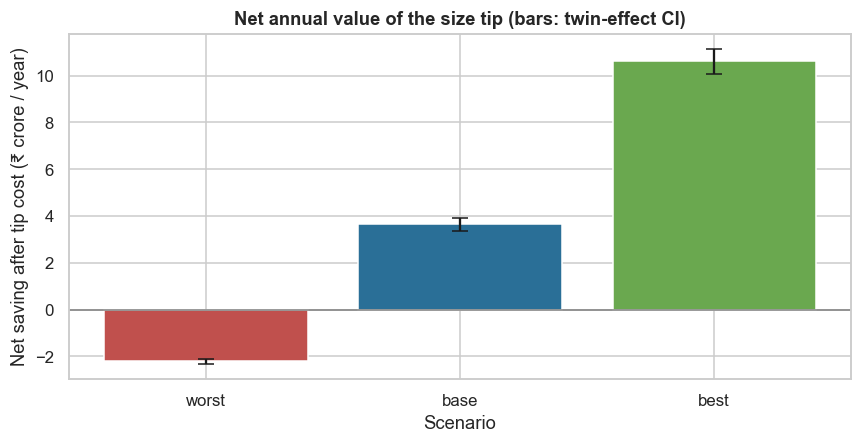

                       orders flagged  flag rate  precision of direction  returns avoided per 100 flagged (full follow)
category                                                                                                               
Women Jacket                     4847     0.3365                  0.1407                                        11.7805
Women Kurta and Kurti            6092     0.1778                  0.1316                                        12.1963
Men's Jean                       6309     0.2829                  0.1195                                        10.4137
Men's Polo T-shirt               5720     0.3257                  0.1182                                        10.1224

,tip followed,₹ per size return,lost sales on tip,returns avoided per year (lakh),net ₹ crore / year,CI low (effect),CI high (effect)
scenario,,,,,,,
worst,0.1500,280.0000,0.0300,0.8640,-2.2050,-2.3100,-2.1120
base,0.3000,380.0000,0.0150,1.7280,3.6550,3.3700,3.9080
best,0.4500,500.0000,0.0100,2.5920,10.6190,10.0580,11.1200


In [19]:
dt = tips(CAL, TAU); ft = dt != 0; bt, at = twin(dt[ft], idt[ft]); av = bt - at; flag_rate = ft.mean(); base_prec = np.mean(yt[ft] == np.where(dt[ft] > 0, 0, 2))
bs = np.array([av[RNG.integers(0, len(av), len(av))].mean() for _ in range(500)]); print(f"Test: flagged {flag_rate:.2%} of orders ({ft.sum():,}) | precision of direction {base_prec:.1%} | size-return rate among flagged before tip {bt.mean():.1%} -> after (100% follow) {at.mean():.1%} | avoided per flagged order {av.mean():.4f} (95% CI {np.percentile(bs, 2.5):.4f} to {np.percentile(bs, 97.5):.4f})")
def net_cr(avoid, comp, cost, aban, marg=MARG): fl = SCOPE * flag_rate; return (fl * comp * avoid * cost - fl * aban * marg - FIXED) / 1e7
sc_ = {"worst": (0.15, 280.0, 0.03), "base": (COMP, COST, ABAN), "best": (0.45, 500.0, 0.01)}
rows = []
for nm, (c_, k_, a2) in sc_.items():
    rows.append((nm, c_, k_, a2, SCOPE * flag_rate * c_ * av.mean() / 1e5, net_cr(av.mean(), c_, k_, a2), net_cr(np.percentile(bs, 2.5), c_, k_, a2), net_cr(np.percentile(bs, 97.5), c_, k_, a2)))
bz = pd.DataFrame(rows, columns=["scenario", "tip followed", "₹ per size return", "lost sales on tip", "returns avoided per year (lakh)", "net ₹ crore / year", "CI low (effect)", "CI high (effect)"]).set_index("scenario")
fig, ax = plt.subplots(figsize=(8, 4.2)); ax.bar(bz.index, bz["net ₹ crore / year"], color=["#c0504d", "#2a6f97", "#6aa84f"], yerr=[bz["net ₹ crore / year"] - bz["CI low (effect)"], bz["CI high (effect)"] - bz["net ₹ crore / year"]], capsize=5)
ax.axhline(0, color="grey", lw=1); ax.set_xlabel("Scenario"); ax.set_ylabel("Net saving after tip cost (₹ crore / year)"); ax.set_title("Net annual value of the size tip (bars: twin-effect CI)")
plt.tight_layout(); plt.show()
cat_rows = []
for c in range(4):
    m = ft & (P.cat.values[idt] == c); b2, a2_ = twin(dt[m], idt[m]); cat_rows.append((CATS[c], int(m.sum()), m.sum() / (P.cat.values[idt] == c).sum(), np.mean(yt[m] == np.where(dt[m] > 0, 0, 2)), (b2 - a2_).mean() * 100))
print(pd.DataFrame(cat_rows, columns=["category", "orders flagged", "flag rate", "precision of direction", "returns avoided per 100 flagged (full follow)"]).set_index("category").round(4).to_string()); bz.round(3)

**Takeaway (business reading):** on the test period the tip is shown on **25.9% of orders** (22,968), with a direction precision of **12.7%**. If followed by everyone, the size-return rate among flagged orders falls from **13.4% to 2.3%**, or **0.111 returns avoided per tip** (95% CI 0.106 to 0.115). The gain per 100 tips is similar across categories: 11.8 for Women Jacket, 12.2 for Women Kurta and Kurti, 10.4 for Men's Jean and 10.1 for Men's Polo. At 2 crore orders a year the base case avoids about **1.73 lakh returns a year** and nets **₹3.7 crore** (twin-effect CI 3.4 to 3.9) after a ₹1.2 crore running cost. The **worst case loses ₹2.2 crore** (15% follow, ₹280 per return, 3% lost sales) and the best case gains **₹10.6 crore**. The CI covers only the twin's effect estimate, not the assumed costs and follow rate, which dominate the range. The twin assumes a customer who follows a tip moves exactly one size, which real customers may not.

## 10. Recommendation and Decision

**Recommendation**

1. **Build the size tip as a calibrated three-class model** (boosting on customer history, size gap, brand, fabric and review features), recalibrated per period. Rank by calibrated probability, not by macro-F1.
2. **Pilot in two categories** (Men's Polo, where the review gain is largest, and Men's Jean) with a cut-off near the top 5% to 10% of orders (precision 20% to 24%), not the 26% value-optimal cut-off, to protect trust.
3. **Run the A/B test on triggered orders**: about 1,100 flagged orders per arm detect a 20% relative drop in the flagged size-return rate.
4. **Decision rule:** scale a category if at least about 25% of viewers follow the tip, the flagged size-return rate falls by 20% or more, and sales on tipped pages fall by no more than 2%. Stop or raise the cut-off if the net value per tipped order is negative.
5. **Fit the review classifier on platform tags**, not public data, and show review-based tips only where a product has informative reviews. For products without reviews rely on history and brand fit.
6. **KPIs:** size-return rate per category, exchange rate, tip follow rate, add-to-cart on tipped pages, calibration error by month, share of orders on products with no reviews, and the reason-code noise rate from a sampled audit.

## 11. Risks, Limitations and Next Steps

- **Simulated mechanism:** the body-vs-garment gap model, the 50% return share and the size of the review signal are assumptions. Real review text may be vaguer and real returns noisier; the order of the models matters more than the absolute scores.
- **Label noise is a ceiling:** "not returned = fit" hides unhappy customers who keep the item; reason codes can be wrong. Use exchange data, post-delivery fit surveys and sampled manual audits to estimate real noise.
- **The twin assumes a clean response to a tip:** real customers may ignore, misread or over-correct a tip, order two sizes up, or abandon. Only an A/B test measures this (7.8); treat the twin ₹ figure as an upper-quality estimate.
- **Stock-outs and size ranges:** a "size up" tip must check that the next size is in stock and in the size chart.
- **Review quality:** bulk, copied or incentivised reviews dilute the fit signal (we removed generic ones; Case 27 covers fraud). Language drift (Hinglish, new slang) needs periodic retraining.
- **Fairness and trust:** tips that tell a customer to go "up" could feel judgemental; the wording should be about the garment ("runs small"), not the person.
- **Next steps:** replace TF-IDF with a fine-tuned multilingual encoder; add a body-measurement questionnaire for new customers; per-brand shrinkage of fit offsets; run the A/B test on the top two categories first.

## 12. Appendix

| Quantity | Formula |
|---|---|
| Class labels | small if return reason = "size smaller"; large if "size larger"; otherwise fit |
| Macro-F1 | mean of the F1 of the three classes: F1 = 2·TP / (2·TP + FP + FN) |
| Average precision (AP) | area under the precision-recall curve for one class; mAP = mean of AP(small) and AP(large) |
| Odds ratio per size step | exp(β) from logit(P(class)) = β·(ordered size − usual size) + category effects |
| Bootstrap p-value (paired) | 2·(1 + min(#Δ ≤ 0, #Δ ≥ 0)) / (B + 1) |
| Platt scaling | calibrated p = σ(a·logit(p) + b), fitted on validation |
| ECE | Σ (n_bin / n) · |mean predicted − observed rate| over deciles |
| Sample size per arm | n = (z₁₋α/₂ + z₁₋β)² · (p₀q₀ + p₁q₁) / (p₀ − p₁)² |
| Net value | flagged × follow × avoided × cost per return − flagged × abandon × margin − fixed cost |

| Term | Meaning |
|---|---|
| Size and fit recommendation | A tip or choice that helps a customer pick the right size |
| Reason code | The reason a customer gives when returning an order |
| Cold start | No history for a customer, or no reviews for a product |
| Macro-F1 | F1 averaged over classes with equal weight, so small classes count |
| Class-balanced weighting | Giving rare classes more weight in training so the model does not ignore them |
| Platt scaling | Fixing a model's probabilities with a small logistic regression |
| Triggered analysis | Analysing only the orders where the treatment could have appeared |
| Digital twin | A simulation where the true behaviour is known, so a change can be tested without a live experiment |